In [2]:
!pip install scanpy

In [3]:
import scanpy as sc

Matplotlib is building the font cache; this may take a moment.


In [4]:
import scanpy as sc

# Relative to your current working directory
adata = sc.read_10x_mtx(
    './GSE141578_RAW_split/GSM4208766_CSF14_filtered_feature_bc_matrix',
    var_names='gene_symbols',
    cache=True
)

In [5]:
adata.obs

""
AAACCTGAGACCCACC-1
AAACCTGAGAGGTTGC-1
AAACCTGAGCCACCTG-1
AAACCTGAGCGCCTTG-1
AAACCTGCAGATCTGT-1
...
TTTGTCAAGTGAACGC-1
TTTGTCAGTCCAGTGC-1
TTTGTCAGTCGCGTGT-1
TTTGTCAGTCTTTCAT-1


In [6]:
adata.var

,gene_ids,feature_types
MIR1302-2HG,ENSG00000243485,Gene Expression
FAM138A,ENSG00000237613,Gene Expression
OR4F5,ENSG00000186092,Gene Expression
AL627309.1,ENSG00000238009,Gene Expression
AL627309.3,ENSG00000239945,Gene Expression
...,...,...
AC233755.2,ENSG00000277856,Gene Expression
AC233755.1,ENSG00000275063,Gene Expression
AC240274.1,ENSG00000271254,Gene Expression
AC213203.1,ENSG00000277475,Gene Expression


In [7]:
adata.X.shape

(1518, 33538)

# Doublet removal - optional but preferred

In [8]:
!pip install scvi-tools

  Using cached docrep-0.3.2.tar.gz (33 kB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Using cached pyro_ppl-1.9.1-py3-none-any.whl.metadata (7.8 kB)
  Using cached rich-15.0.0-py3-none-any.whl.metadata (18 kB)
  Using cached setuptools-84.0.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached aiosignal-1.4.0-py3-none-any.whl.metadata (3.7 kB)
  Using cached attrs-26.1.0-py3-none-any.whl.metadata (8.8 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
INFO: pip is looking at multiple versions of mudata to determine which version is compatible with other requirements. This could take a while.
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached pyro_api-0.1.2-py3-none-any.whl.metadata (2.5 kB)
  Using cached mdurl-0.1.2-py3-none-

In [9]:
import scvi

/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [10]:
adata

AnnData object with n_obs × n_vars = 1518 × 33538
    var: 'gene_ids', 'feature_types'
    layers: None (.X)

In [11]:
sc.pp.filter_genes(adata, min_cells = 10)

In [12]:
sc.pp.highly_variable_genes(adata, n_top_genes = 2000, subset = True, flavor = 'seurat_v3')

In [13]:
scvi.model.SCVI.setup_anndata(adata)
vae = scvi.model.SCVI(adata)
vae.train()

/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scvi/data/fields/_layer_field.py:115: UserWarning: Training will be faster when sparse matrix is formatted as CSR. It is safe to cast before model initialization.
  _verify_and_correct_data_format(adata, self.attr_name, self.attr_key)
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been automatically set to `cpu` although 'mps' exists. If you wish to run on mps backend, use explicitly accelerator='mps' in train function.In future releases it will become default for mps supported machines.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: False
TPU available: False, using: 0 TPU cores
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/lightning/pytorch/trainer/setup.py:175: GPU available but not used. You can set it by doing `Trainer(accelerator='gpu')`.
💡 Tip: For seamless cloud logging an

Epoch 400/400: 100%|██████████| 400/400 [00:42<00:00,  9.56it/s, v_num=1, train_loss=420]

`Trainer.fit` stopped: `max_epochs=400` reached.


Epoch 400/400: 100%|██████████| 400/400 [00:42<00:00,  9.47it/s, v_num=1, train_loss=420]


In [14]:
solo = scvi.external.SOLO.from_scvi_model(vae)
solo.train(max_epochs=200)

INFO     Creating doublets, preparing SOLO model.                                                                  


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scvi/data/fields/_layer_field.py:115: UserWarning: Training will be faster when sparse matrix is formatted as CSR. It is safe to cast before model initialization.
  _verify_and_correct_data_format(adata, self.attr_name, self.attr_key)
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been automatically set to `cpu` although 'mps' exists. If you wish to run on mps backend, use explicitly accelerator='mps' in train function.In future releases it will become default for mps supported machines.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: False
TPU available: False, using: 0 TPU cores
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/lightning/pytorch/trainer/setup.py:175: GPU available but not used. You can set it by doing `Trainer(accelerator='gpu')`.
💡 Tip: For seamless cloud logging an

Epoch 102/200:  51%|█████     | 102/200 [00:02<00:02, 42.54it/s, v_num=1, train_loss_step=1.13, train_loss_epoch=0.255] 
Monitored metric validation_loss did not improve in the last 30 records. Best score: 0.241. Signaling Trainer to stop.


In [15]:
df = solo.predict()
df['prediction'] = solo.predict(soft = False)

df.index = df.index.map(lambda x: x[:-2])

df

/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/torch/utils/_contextlib.py:124: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabilities. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/torch/utils/_contextlib.py:124: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabilities. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)


,doublet,singlet,prediction
AAACCTGAGACCCACC,0.029392,0.970608,singlet
AAACCTGAGAGGTTGC,0.055599,0.944401,singlet
AAACCTGAGCCACCTG,0.351002,0.648998,singlet
AAACCTGAGCGCCTTG,0.054645,0.945355,singlet
AAACCTGCAGATCTGT,0.000959,0.999041,singlet
...,...,...,...
TTTGTCAAGTGAACGC,0.009216,0.990784,singlet
TTTGTCAGTCCAGTGC,0.116837,0.883163,singlet
TTTGTCAGTCGCGTGT,0.090539,0.909461,singlet
TTTGTCAGTCTTTCAT,0.139321,0.860679,singlet


In [16]:
df.groupby('prediction').count()

,doublet,singlet
prediction,,
doublet,263,263
singlet,1255,1255


In [17]:
df['dif'] = df.doublet - df.singlet
df

,doublet,singlet,prediction,dif
AAACCTGAGACCCACC,0.029392,0.970608,singlet,-0.941217
AAACCTGAGAGGTTGC,0.055599,0.944401,singlet,-0.888802
AAACCTGAGCCACCTG,0.351002,0.648998,singlet,-0.297996
AAACCTGAGCGCCTTG,0.054645,0.945355,singlet,-0.890710
AAACCTGCAGATCTGT,0.000959,0.999041,singlet,-0.998081
...,...,...,...,...
TTTGTCAAGTGAACGC,0.009216,0.990784,singlet,-0.981569
TTTGTCAGTCCAGTGC,0.116837,0.883163,singlet,-0.766326
TTTGTCAGTCGCGTGT,0.090539,0.909461,singlet,-0.818923
TTTGTCAGTCTTTCAT,0.139321,0.860679,singlet,-0.721359


In [18]:
import seaborn as sns

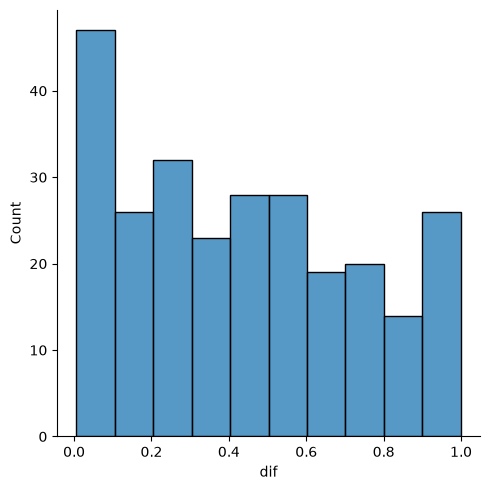

In [19]:
sns.displot(df[df.prediction == 'doublet'], x = 'dif')

In [20]:
doublets = df[(df.prediction == 'doublet') & (df.dif > 1)]
doublets

,doublet,singlet,prediction,dif


In [21]:
# Relative to your current working directory
adata = sc.read_10x_mtx(
    './GSE141578_RAW_split/GSM4208766_CSF14_filtered_feature_bc_matrix',
    var_names='gene_symbols',
    cache=True
)

In [22]:
adata.obs

""
AAACCTGAGACCCACC-1
AAACCTGAGAGGTTGC-1
AAACCTGAGCCACCTG-1
AAACCTGAGCGCCTTG-1
AAACCTGCAGATCTGT-1
...
TTTGTCAAGTGAACGC-1
TTTGTCAGTCCAGTGC-1
TTTGTCAGTCGCGTGT-1
TTTGTCAGTCTTTCAT-1


In [23]:
adata.obs['doublet'] = adata.obs.index.isin(doublets.index)

In [24]:
adata.obs

,doublet
AAACCTGAGACCCACC-1,False
AAACCTGAGAGGTTGC-1,False
AAACCTGAGCCACCTG-1,False
AAACCTGAGCGCCTTG-1,False
AAACCTGCAGATCTGT-1,False
...,...
TTTGTCAAGTGAACGC-1,False
TTTGTCAGTCCAGTGC-1,False
TTTGTCAGTCGCGTGT-1,False
TTTGTCAGTCTTTCAT-1,False


In [25]:
adata = adata[~adata.obs.doublet]

In [26]:
adata

View of AnnData object with n_obs × n_vars = 1518 × 33538
    obs: 'doublet'
    var: 'gene_ids', 'feature_types'
    layers: None (.X)

# Preprocessing

In [27]:
adata.var[adata.var.index.str.startswith('MT-')]

,gene_ids,feature_types
MT-ND1,ENSG00000198888,Gene Expression
MT-ND2,ENSG00000198763,Gene Expression
MT-CO1,ENSG00000198804,Gene Expression
MT-CO2,ENSG00000198712,Gene Expression
MT-ATP8,ENSG00000228253,Gene Expression
MT-ATP6,ENSG00000198899,Gene Expression
MT-CO3,ENSG00000198938,Gene Expression
MT-ND3,ENSG00000198840,Gene Expression
MT-ND4L,ENSG00000212907,Gene Expression
MT-ND4,ENSG00000198886,Gene Expression


In [28]:
adata.var['mt'] = adata.var.index.str.startswith('MT-')

/var/folders/ls/zbhsy_7j4q34qfbbpfg9xhg00000gn/T/ipykernel_79369/310233584.py:1: ImplicitModificationWarning: Trying to modify attribute `.var` of view, initializing view as actual.
  adata.var['mt'] = adata.var.index.str.startswith('MT-')


In [29]:
adata.var

,gene_ids,feature_types,mt
MIR1302-2HG,ENSG00000243485,Gene Expression,False
FAM138A,ENSG00000237613,Gene Expression,False
OR4F5,ENSG00000186092,Gene Expression,False
AL627309.1,ENSG00000238009,Gene Expression,False
AL627309.3,ENSG00000239945,Gene Expression,False
...,...,...,...
AC233755.2,ENSG00000277856,Gene Expression,False
AC233755.1,ENSG00000275063,Gene Expression,False
AC240274.1,ENSG00000271254,Gene Expression,False
AC213203.1,ENSG00000277475,Gene Expression,False


In [30]:
import pandas as pd

In [31]:
ribo_url = "http://software.broadinstitute.org/gsea/msigdb/download_geneset.jsp?geneSetName=KEGG_RIBOSOME&fileType=txt"

In [32]:
ribo_genes = pd.read_table(ribo_url, skiprows=2, header = None)
ribo_genes

,0
0,FAU
1,MRPL13
2,RPL10
3,RPL10A
4,RPL10L
...,...
83,RPS9
84,RPSA
85,RSL24D1
86,RSL24D1P11


In [33]:
adata.var['ribo'] = adata.var_names.isin(ribo_genes[0].values)

In [34]:
adata.obs

,doublet
AAACCTGAGACCCACC-1,False
AAACCTGAGAGGTTGC-1,False
AAACCTGAGCCACCTG-1,False
AAACCTGAGCGCCTTG-1,False
AAACCTGCAGATCTGT-1,False
...,...
TTTGTCAAGTGAACGC-1,False
TTTGTCAGTCCAGTGC-1,False
TTTGTCAGTCGCGTGT-1,False
TTTGTCAGTCTTTCAT-1,False


In [35]:
adata.var

,gene_ids,feature_types,mt,ribo
MIR1302-2HG,ENSG00000243485,Gene Expression,False,False
FAM138A,ENSG00000237613,Gene Expression,False,False
OR4F5,ENSG00000186092,Gene Expression,False,False
AL627309.1,ENSG00000238009,Gene Expression,False,False
AL627309.3,ENSG00000239945,Gene Expression,False,False
...,...,...,...,...
AC233755.2,ENSG00000277856,Gene Expression,False,False
AC233755.1,ENSG00000275063,Gene Expression,False,False
AC240274.1,ENSG00000271254,Gene Expression,False,False
AC213203.1,ENSG00000277475,Gene Expression,False,False


In [36]:
sc.pp.calculate_qc_metrics(adata, qc_vars=['mt', 'ribo'], percent_top=None, log1p=False, inplace=True)

In [37]:
adata.var.sort_values('n_cells_by_counts')

,gene_ids,feature_types,mt,ribo,n_cells_by_counts,mean_counts,pct_dropout_by_counts,total_counts
MIR1302-2HG,ENSG00000243485,Gene Expression,False,False,0,0.000000,100.000000,0.0
MALRD1,ENSG00000204740,Gene Expression,False,False,0,0.000000,100.000000,0.0
AL512641.1,ENSG00000234244,Gene Expression,False,False,0,0.000000,100.000000,0.0
AL450384.1,ENSG00000225527,Gene Expression,False,False,0,0.000000,100.000000,0.0
AL450384.2,ENSG00000240291,Gene Expression,False,False,0,0.000000,100.000000,0.0
...,...,...,...,...,...,...,...,...
MT-CO2,ENSG00000198712,Gene Expression,True,False,1513,26.067852,0.329381,39571.0
MT-ND4L,ENSG00000212907,Gene Expression,True,False,1513,13.208827,0.329381,20051.0
MT-CYB,ENSG00000198727,Gene Expression,True,False,1513,15.811594,0.329381,24002.0
MT-CO3,ENSG00000198938,Gene Expression,True,False,1514,18.997364,0.263505,28838.0


In [38]:
sc.pp.filter_genes(adata, min_cells=3)

In [39]:
adata.var.sort_values('n_cells_by_counts')

,gene_ids,feature_types,mt,ribo,n_cells_by_counts,mean_counts,pct_dropout_by_counts,total_counts,n_cells
TSPAN15,ENSG00000099282,Gene Expression,False,False,3,0.001976,99.802372,3.0,3
PDE1B,ENSG00000123360,Gene Expression,False,False,3,0.001976,99.802372,3.0,3
MON1A,ENSG00000164077,Gene Expression,False,False,3,0.001976,99.802372,3.0,3
PMEL,ENSG00000185664,Gene Expression,False,False,3,0.001976,99.802372,3.0,3
MISP3,ENSG00000141854,Gene Expression,False,False,3,0.001976,99.802372,3.0,3
...,...,...,...,...,...,...,...,...,...
MT-CYB,ENSG00000198727,Gene Expression,True,False,1513,15.811594,0.329381,24002.0,1513
MT-CO2,ENSG00000198712,Gene Expression,True,False,1513,26.067852,0.329381,39571.0,1513
MT-ND4L,ENSG00000212907,Gene Expression,True,False,1513,13.208827,0.329381,20051.0,1513
MT-CO3,ENSG00000198938,Gene Expression,True,False,1514,18.997364,0.263505,28838.0,1514


In [40]:
adata.obs.sort_values('n_genes_by_counts')

,doublet,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,total_counts_ribo,pct_counts_ribo
TGATTTCCACCAGGCT-1,False,28,2389.0,0.0,0.000000,9.0,0.376727
TCATTACTCTGGTATG-1,False,221,905.0,0.0,0.000000,564.0,62.320442
GTGTGCGAGTAACCCT-1,False,260,544.0,239.0,43.933823,6.0,1.102941
CTGAAGTCAAGAGGCT-1,False,265,518.0,226.0,43.629341,8.0,1.544402
CAGATCATCGTAGGAG-1,False,265,636.0,43.0,6.761006,299.0,47.012581
...,...,...,...,...,...,...,...
AACCATGTCTTGCAAG-1,False,2150,10005.0,643.0,6.426786,3494.0,34.922539
GCTTGAACATAACCTG-1,False,2165,8503.0,474.0,5.574503,2112.0,24.838293
TACTTACCACATCCAA-1,False,2170,9579.0,366.0,3.820858,3232.0,33.740471
GTACTTTAGTTGAGAT-1,False,2549,11149.0,838.0,7.516369,2376.0,21.311327


In [41]:
sc.pp.filter_cells(adata, min_genes=200)

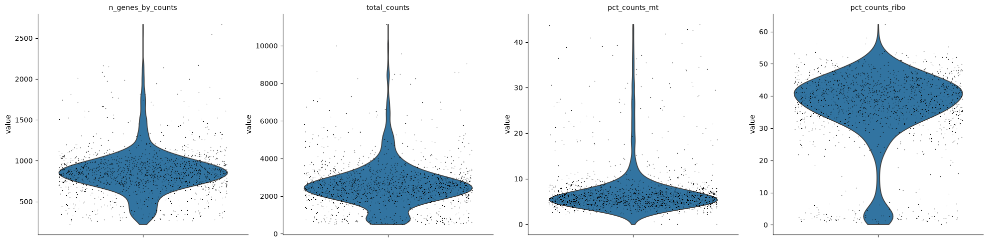

In [42]:
sc.pl.violin(adata, ['n_genes_by_counts', 'total_counts', 'pct_counts_mt', 'pct_counts_ribo'], 
             jitter=0.4, multi_panel=True)

In [43]:
import numpy as np

In [44]:
upper_lim = np.quantile(adata.obs.n_genes_by_counts.values, .98)
#upper_lim = 3000

In [45]:
upper_lim

np.float64(1678.1600000000008)

In [46]:
adata = adata[adata.obs.n_genes_by_counts < upper_lim]

In [47]:
adata.obs

,doublet,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,total_counts_ribo,pct_counts_ribo,n_genes
AAACCTGAGACCCACC-1,False,739,1738.0,85.0,4.890679,576.0,33.141541,738
AAACCTGAGAGGTTGC-1,False,692,2036.0,202.0,9.921414,868.0,42.632614,689
AAACCTGAGCCACCTG-1,False,937,3015.0,144.0,4.776119,1441.0,47.794361,936
AAACCTGAGCGCCTTG-1,False,832,3437.0,153.0,4.451557,1851.0,53.855103,832
AAACCTGCAGATCTGT-1,False,735,1601.0,132.0,8.244846,520.0,32.479702,734
...,...,...,...,...,...,...,...,...
TTTGTCAAGTGAACGC-1,False,829,2217.0,136.0,6.134416,865.0,39.016689,829
TTTGTCAGTCCAGTGC-1,False,854,2099.0,121.0,5.764650,631.0,30.061934,853
TTTGTCAGTCGCGTGT-1,False,743,2401.0,123.0,5.122865,1139.0,47.438568,742
TTTGTCAGTCTTTCAT-1,False,735,1656.0,308.0,18.599033,446.0,26.932367,730


In [48]:
adata = adata[adata.obs.pct_counts_mt < 20]

In [49]:
adata = adata[adata.obs.pct_counts_ribo < 55]

In [50]:
adata

View of AnnData object with n_obs × n_vars = 1406 × 12130
    obs: 'doublet', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'n_genes'
    var: 'gene_ids', 'feature_types', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'
    layers: None (.X)

# Normalization

In [52]:
adata.X.sum(axis = 1)

matrix([[1737.],
        [2033.],
        [3014.],
        ...,
        [2400.],
        [1650.],
        [3220.]], shape=(1406, 1), dtype=float32)

In [53]:
sc.pp.normalize_total(adata, target_sum=1e4) #normalize every cell to 10,000 UMI

/var/folders/ls/zbhsy_7j4q34qfbbpfg9xhg00000gn/T/ipykernel_79369/2754614204.py:1: UserWarning: Received a view of an AnnData. Making a copy.
  sc.pp.normalize_total(adata, target_sum=1e4) #normalize every cell to 10,000 UMI


In [54]:
adata.X

<Compressed Sparse Row sparse matrix of dtype 'float32'
	with 1214429 stored elements and shape (1406, 12130)>

In [55]:
adata.X.sum(axis = 1)

matrix([[ 9999.999],
        [ 9999.999],
        [ 9999.999],
        ...,
        [10000.   ],
        [10000.   ],
        [10000.   ]], shape=(1406, 1), dtype=float32)

In [56]:
sc.pp.log1p(adata) #change to log counts

In [57]:
adata.X.sum(axis = 1)

matrix([[1674.1396],
        [1518.7977],
        [1741.0884],
        ...,
        [1544.2565],
        [1652.8444],
        [1979.6316]], shape=(1406, 1), dtype=float32)

In [58]:
adata.raw = adata

# Clustering

In [59]:
sc.pp.highly_variable_genes(adata, n_top_genes = 2000)

In [60]:
adata.var

,gene_ids,feature_types,mt,ribo,n_cells_by_counts,mean_counts,pct_dropout_by_counts,total_counts,n_cells,highly_variable,means,dispersions,dispersions_norm
AL669831.5,ENSG00000237491,Gene Expression,False,False,4,0.002635,99.736495,4.0,4,False,0.005604,1.012631,-1.819111
LINC00115,ENSG00000225880,Gene Expression,False,False,19,0.012516,98.748353,19.0,19,False,0.038085,1.265198,-1.056760
NOC2L,ENSG00000188976,Gene Expression,False,False,184,0.129117,87.878788,196.0,184,False,0.414674,1.501414,-0.569449
ISG15,ENSG00000187608,Gene Expression,False,False,248,0.196311,83.662714,298.0,248,False,0.556058,1.554650,-0.317970
C1orf159,ENSG00000131591,Gene Expression,False,False,12,0.007905,99.209486,12.0,12,False,0.032211,1.754866,0.421257
...,...,...,...,...,...,...,...,...,...,...,...,...,...
MT-ND5,ENSG00000198786,Gene Expression,True,False,1496,8.252306,1.449275,12527.0,1496,True,3.500684,2.568942,1.616593
MT-ND6,ENSG00000198695,Gene Expression,True,False,1356,3.565876,10.671937,5413.0,1356,True,2.711060,2.423915,2.143787
MT-CYB,ENSG00000198727,Gene Expression,True,False,1513,15.811594,0.329381,24002.0,1513,True,4.159997,3.009331,2.516085
MAFIP,ENSG00000274847,Gene Expression,False,False,9,0.005929,99.407115,9.0,9,False,0.029128,1.784601,0.511010


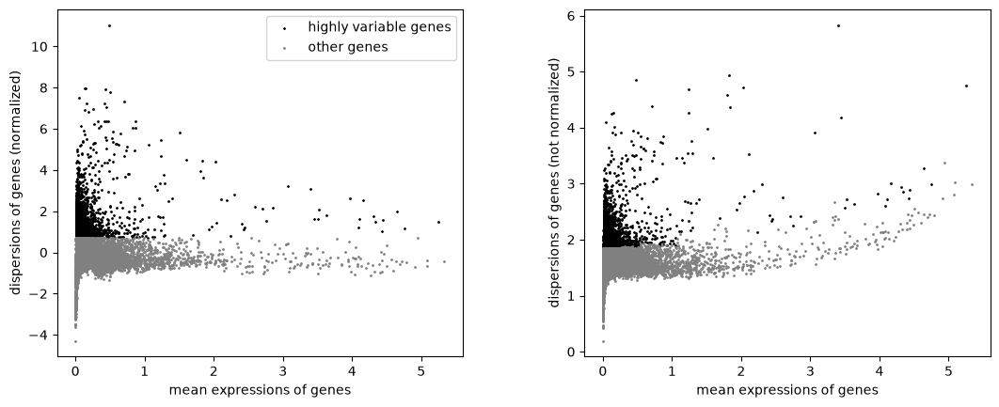

In [61]:
sc.pl.highly_variable_genes(adata)

In [62]:
adata = adata[:, adata.var.highly_variable]

In [63]:
sc.pp.regress_out(adata, ['total_counts', 'pct_counts_mt', 'pct_counts_ribo'])

/var/folders/ls/zbhsy_7j4q34qfbbpfg9xhg00000gn/T/ipykernel_79369/2141330248.py:1: UserWarning: Received a view of an AnnData. Making a copy.
  sc.pp.regress_out(adata, ['total_counts', 'pct_counts_mt', 'pct_counts_ribo'])
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scanpy/preprocessing/_simple.py:660: NumbaPerformanceWarning: '@' is faster on contiguous arrays, called on (Array(float64, 1, 'A', False, aligned=True), Array(float64, 2, 'C', False, aligned=True))
  data[i] -= regressor[i] @ coeff
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scanpy/preprocessing/_simple.py:660: NumbaPerformanceWarning: '@' is faster on contiguous arrays, called on (Array(float64, 1, 'A', False, aligned=True), Array(float64, 2, 'C', False, aligned=True))
  data[i] -= regressor[i] @ coeff


In [64]:
adata

AnnData object with n_obs × n_vars = 1406 × 2000
    obs: 'doublet', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'n_genes'
    var: 'gene_ids', 'feature_types', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'log1p', 'hvg'
    layers: None (.X)

In [65]:
sc.pp.scale(adata, max_value=10)

In [66]:
sc.tl.pca(adata, svd_solver='arpack')

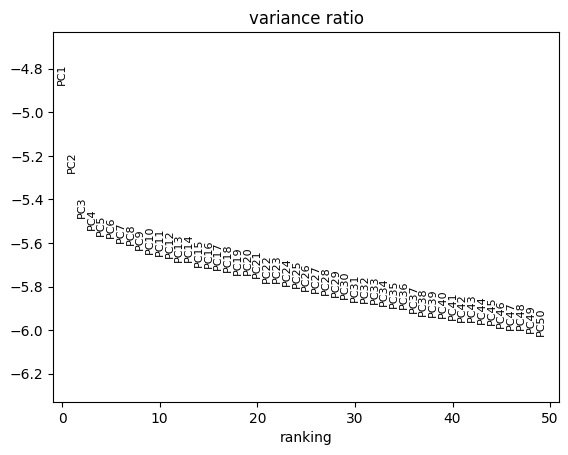

In [220]:
sc.pl.pca_variance_ratio(adata, log=True, n_pcs = 50)

In [67]:
sc.pp.neighbors(adata, n_pcs = 35)

In [69]:
adata

AnnData object with n_obs × n_vars = 1406 × 2000
    obs: 'doublet', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'n_genes'
    var: 'gene_ids', 'feature_types', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'mean', 'std'
    uns: 'log1p', 'hvg', 'pca', 'neighbors'
    obsm: 'X_pca'
    varm: 'PCs'
    obsp: 'distances', 'connectivities'
    layers: None (.X)

In [70]:
sc.tl.umap(adata)

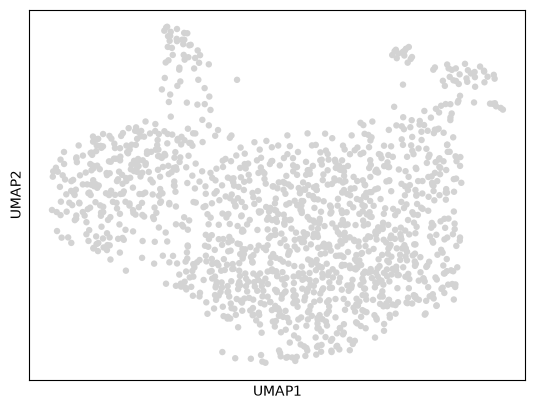

In [71]:
sc.pl.umap(adata)

In [77]:
!pip install leidenalg

  Using cached leidenalg-0.12.0-cp38-abi3-macosx_11_0_arm64.whl.metadata (10 kB)
  Using cached igraph-1.0.0-cp39-abi3-macosx_11_0_arm64.whl.metadata (4.4 kB)
  Using cached texttable-1.7.0-py2.py3-none-any.whl.metadata (9.8 kB)
Using cached leidenalg-0.12.0-cp38-abi3-macosx_11_0_arm64.whl (1.9 MB)
Using cached igraph-1.0.0-cp39-abi3-macosx_11_0_arm64.whl (2.0 MB)
Using cached texttable-1.7.0-py2.py3-none-any.whl (10 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [leidenalg]


In [78]:
sc.tl.leiden(adata, resolution = 0.5)

/var/folders/ls/zbhsy_7j4q34qfbbpfg9xhg00000gn/T/ipykernel_79369/3246266323.py:1: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata, resolution = 0.5)


In [79]:
adata.obs

,doublet,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,total_counts_ribo,pct_counts_ribo,n_genes,leiden
AAACCTGAGACCCACC-1,False,739,1738.0,85.0,4.890679,576.0,33.141541,738,2
AAACCTGAGAGGTTGC-1,False,692,2036.0,202.0,9.921414,868.0,42.632614,689,1
AAACCTGAGCCACCTG-1,False,937,3015.0,144.0,4.776119,1441.0,47.794361,936,1
AAACCTGAGCGCCTTG-1,False,832,3437.0,153.0,4.451557,1851.0,53.855103,832,0
AAACCTGCAGATCTGT-1,False,735,1601.0,132.0,8.244846,520.0,32.479702,734,3
...,...,...,...,...,...,...,...,...,...
TTTGTCAAGTGAACGC-1,False,829,2217.0,136.0,6.134416,865.0,39.016689,829,1
TTTGTCAGTCCAGTGC-1,False,854,2099.0,121.0,5.764650,631.0,30.061934,853,0
TTTGTCAGTCGCGTGT-1,False,743,2401.0,123.0,5.122865,1139.0,47.438568,742,1
TTTGTCAGTCTTTCAT-1,False,735,1656.0,308.0,18.599033,446.0,26.932367,730,3


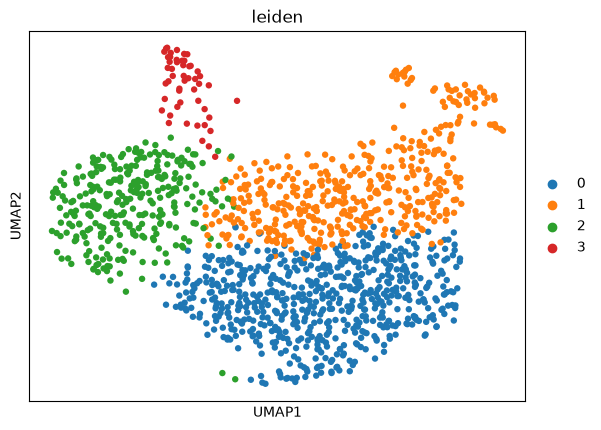

In [80]:
sc.pl.umap(adata, color=['leiden'])

# Integration

In [85]:
##### New #####

from pathlib import Path
import gzip
import shutil
import scanpy as sc
import scvi
import numpy as np

def _gzip_if_needed(sample_dir: Path):
    # Make files compatible with sc.read_10x_mtx when only uncompressed files exist
    for fn in ["matrix.mtx", "features.tsv", "barcodes.tsv", "genes.tsv"]:
        f = sample_dir / fn
        gz = sample_dir / f"{fn}.gz"
        if f.exists() and not gz.exists():
            with open(f, "rb") as fin, gzip.open(gz, "wb") as fout:
                shutil.copyfileobj(fin, fout)

def pp_10x(sample_dir):
    sample_dir = Path(sample_dir)
    _gzip_if_needed(sample_dir)

    # Read 10x matrix
    adata = sc.read_10x_mtx(sample_dir, var_names="gene_symbols", cache=True)

    # Sample name from folder: GSM4208766_CSF14_filtered_feature_bc_matrix -> CSF14
    parts = sample_dir.name.split("_")
    sample_name = parts[1] if len(parts) > 1 else sample_dir.name
    adata.obs["Sample"] = sample_name

    # Doublet removal (same logic as before)
    sc.pp.filter_genes(adata, min_cells=10)
    sc.pp.highly_variable_genes(adata, n_top_genes=2000, subset=True, flavor="seurat_v3")
    from scipy.sparse import csr_matrix

    # Speed hint from scvi warning
    if not isinstance(adata.X, csr_matrix):
        adata.X = csr_matrix(adata.X)

    # SCVI on Apple Silicon GPU (MPS)
    scvi.model.SCVI.setup_anndata(adata)
    vae = scvi.model.SCVI(adata)
    vae.train(
        accelerator="mps",   # use Apple GPU
        devices=1,
        max_epochs=400,
        log_every_n_steps=1
    )

    solo = scvi.external.SOLO.from_scvi_model(vae)
    solo.train(accelerator="mps", devices=1)


    # Be explicit about SOLO output type
    df = solo.predict(soft=True)  # probabilities
    # old behavior (logits), if needed:
    # df = solo.predict(soft=True, return_logits=True)
    df["prediction"] = solo.predict(soft=False)
    df.index = df.index.map(lambda x: x[:-2])   # keep your original indexing logic
    df["dif"] = df.doublet - df.singlet
    doublets = df[(df.prediction == "doublet") & (df.dif > 1)]

    # Reload full data before filtering cells
    adata = sc.read_10x_mtx(sample_dir, var_names="gene_symbols", cache=True)
    adata.obs["Sample"] = sample_name
    adata.obs["doublet"] = adata.obs.index.isin(doublets.index)
    adata = adata[~adata.obs.doublet].copy()

    # QC
    sc.pp.filter_cells(adata, min_genes=200)
    adata.var["mt"] = adata.var_names.str.startswith("MT-")
    adata.var["ribo"] = adata.var_names.isin(ribo_genes[0].values)
    sc.pp.calculate_qc_metrics(adata, qc_vars=["mt", "ribo"], percent_top=None, log1p=False, inplace=True)

    upper_lim = np.quantile(adata.obs.n_genes_by_counts.values, 0.98)
    adata = adata[adata.obs.n_genes_by_counts < upper_lim]
    adata = adata[adata.obs.pct_counts_mt < 40]
    adata = adata[adata.obs.pct_counts_ribo < 55]

    return adata



In [86]:
import os

In [87]:
# out = []
# for file in os.listdir('raw_counts/'):
#    out.append(pp('raw_counts/' + file))

In [88]:
# Replace old raw_counts loop
base_dir = Path("/Users/prokash/DWCT/Thesis/Demo_PD_GSE141578/scRNA-seq_scanpy/GSE141578_RAW_split")
sample_dirs = sorted([p for p in base_dir.iterdir() if p.is_dir() and p.name.endswith("_filtered_feature_bc_matrix")])

out = [pp_10x(p) for p in sample_dirs]



/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch operations are supported with this backend. as a result, some models might be slower and less accurate than usual. Please verify your analysis!Refer to https://github.com/pytorch/pytorch/issues/77764 for more details.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/pr

Epoch 400/400: 100%|██████████| 400/400 [00:47<00:00,  6.71it/s, v_num=1, train_loss=417]

`Trainer.fit` stopped: `max_epochs=400` reached.


Epoch 400/400: 100%|██████████| 400/400 [00:47<00:00,  8.50it/s, v_num=1, train_loss=417]
INFO     Creating doublets, preparing SOLO model.                                                                  


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch operations are supported with this backend. as a result, some models might be slower and less accurate than usual. Please verify your analysis!Refer to https://github.com/pytorch/pytorch/issues/77764 for more details.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/pr

Epoch 93/400:  23%|██▎       | 93/400 [00:07<00:25, 12.01it/s, v_num=1, train_loss_step=0.0681, train_loss_epoch=0.247] 
Monitored metric validation_loss did not improve in the last 30 records. Best score: 0.268. Signaling Trainer to stop.


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/torch/utils/_contextlib.py:124: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabilities. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/torch/utils/_contextlib.py:124: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabilities. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scvi/dataloaders/_data_splitting.py:258: UserWarning: 2 cells moved from training set to validation set. if you want to avoid it ple

Epoch 400/400: 100%|██████████| 400/400 [00:16<00:00, 27.68it/s, v_num=1, train_loss=539]

`Trainer.fit` stopped: `max_epochs=400` reached.


Epoch 400/400: 100%|██████████| 400/400 [00:16<00:00, 24.77it/s, v_num=1, train_loss=539]
INFO     Creating doublets, preparing SOLO model.                                                                  


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch operations are supported with this backend. as a result, some models might be slower and less accurate than usual. Please verify your analysis!Refer to https://github.com/pytorch/pytorch/issues/77764 for more details.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/pr

Epoch 31/400:   8%|▊         | 31/400 [00:01<00:17, 21.41it/s, v_num=1, train_loss_step=0.367, train_loss_epoch=0.327]
Monitored metric validation_loss did not improve in the last 30 records. Best score: 0.606. Signaling Trainer to stop.


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/torch/utils/_contextlib.py:124: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabilities. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/torch/utils/_contextlib.py:124: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabilities. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch operations are sup

Epoch 400/400: 100%|██████████| 400/400 [00:38<00:00,  9.91it/s, v_num=1, train_loss=549]

`Trainer.fit` stopped: `max_epochs=400` reached.


Epoch 400/400: 100%|██████████| 400/400 [00:38<00:00, 10.30it/s, v_num=1, train_loss=549]
INFO     Creating doublets, preparing SOLO model.                                                                  


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch operations are supported with this backend. as a result, some models might be slower and less accurate than usual. Please verify your analysis!Refer to https://github.com/pytorch/pytorch/issues/77764 for more details.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/pr

Epoch 400/400: 100%|██████████| 400/400 [00:23<00:00, 17.80it/s, v_num=1, train_loss_step=0.181, train_loss_epoch=0.245]

`Trainer.fit` stopped: `max_epochs=400` reached.


Epoch 400/400: 100%|██████████| 400/400 [00:23<00:00, 17.36it/s, v_num=1, train_loss_step=0.181, train_loss_epoch=0.245]


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/torch/utils/_contextlib.py:124: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabilities. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/torch/utils/_contextlib.py:124: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabilities. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch operations are sup

Epoch 400/400: 100%|██████████| 400/400 [00:26<00:00, 11.35it/s, v_num=1, train_loss=575]

`Trainer.fit` stopped: `max_epochs=400` reached.


Epoch 400/400: 100%|██████████| 400/400 [00:26<00:00, 15.21it/s, v_num=1, train_loss=575]
INFO     Creating doublets, preparing SOLO model.                                                                  


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch operations are supported with this backend. as a result, some models might be slower and less accurate than usual. Please verify your analysis!Refer to https://github.com/pytorch/pytorch/issues/77764 for more details.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/pr

Epoch 198/400:  50%|████▉     | 198/400 [00:11<00:11, 17.46it/s, v_num=1, train_loss_step=0.283, train_loss_epoch=0.256]
Monitored metric validation_loss did not improve in the last 30 records. Best score: 0.273. Signaling Trainer to stop.


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/torch/utils/_contextlib.py:124: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabilities. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/torch/utils/_contextlib.py:124: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabilities. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch operations are sup

Epoch 400/400: 100%|██████████| 400/400 [00:45<00:00,  7.00it/s, v_num=1, train_loss=705]

`Trainer.fit` stopped: `max_epochs=400` reached.


Epoch 400/400: 100%|██████████| 400/400 [00:45<00:00,  8.81it/s, v_num=1, train_loss=705]
INFO     Creating doublets, preparing SOLO model.                                                                  


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch operations are supported with this backend. as a result, some models might be slower and less accurate than usual. Please verify your analysis!Refer to https://github.com/pytorch/pytorch/issues/77764 for more details.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/pr

Epoch 370/400:  92%|█████████▎| 370/400 [00:22<00:01, 16.56it/s, v_num=1, train_loss_step=0.218, train_loss_epoch=0.292] 
Monitored metric validation_loss did not improve in the last 30 records. Best score: 0.328. Signaling Trainer to stop.


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/torch/utils/_contextlib.py:124: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabilities. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/torch/utils/_contextlib.py:124: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabilities. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)


In [89]:
# adata = sc.concat(out)

# Replace old sc.concat(out)
adata = sc.concat(
    out,
    label="batch",
    keys=[p.name for p in sample_dirs],
    index_unique="-",   # prevents barcode collisions across samples
)


In [116]:
adata

AnnData object with n_obs × n_vars = 5599 × 8974
    obs: 'Sample', 'doublet', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'batch', '_scvi_batch', '_scvi_labels', 'leiden'
    var: 'n_cells'
    uns: 'log1p', '_scvi_uuid', '_scvi_manager_uuid', 'neighbors', 'umap', 'leiden', 'leiden_colors', 'Sample_colors'
    obsm: '_scvi_extra_categorical_covs', '_scvi_extra_continuous_covs', 'X_scVI', 'X_umap'
    obsp: 'distances', 'connectivities'
    layers: None (.X), 'counts', 'scvi_normalized'

########################################################### All samples ###########################

In [137]:
# filepath: /Users/prokash/DWCT/Thesis/Demo_PD_GSE141578/scRNA-seq_scanpy/single_cell_analysis_GSE141578.ipynb
# ...existing code...
from pathlib import Path
import re
import gzip
import shutil
import numpy as np
import pandas as pd
import scanpy as sc
import scvi
from scipy.sparse import csr_matrix
import torch

BASE_DIR = Path("/Users/prokash/DWCT/Thesis/Demo_PD_GSE141578/scRNA-seq_scanpy/GSE141578_RAW_split")

def _has_10x_files(d: Path):
    has_matrix = (d / "matrix.mtx").exists() or (d / "matrix.mtx.gz").exists()
    has_barcodes = (d / "barcodes.tsv").exists() or (d / "barcodes.tsv.gz").exists()
    has_features = (
        (d / "features.tsv").exists() or (d / "features.tsv.gz").exists() or
        (d / "genes.tsv").exists() or (d / "genes.tsv.gz").exists()
    )
    return has_matrix and has_barcodes and has_features

def _gzip_if_needed(sample_dir: Path):
    for fn in ["matrix.mtx", "features.tsv", "barcodes.tsv", "genes.tsv"]:
        f = sample_dir / fn
        gz = sample_dir / f"{fn}.gz"
        if f.exists() and not gz.exists():
            with open(f, "rb") as fin, gzip.open(gz, "wb") as fout:
                shutil.copyfileobj(fin, fout)

def find_10x_dirs(base_dir: Path):
    dirs = []
    for d in base_dir.rglob("*"):
        if d.is_dir() and _has_10x_files(d):
            dirs.append(d)
    return sorted(set(dirs))

def sample_name_from_dir(sample_dir: Path):
    # e.g. GSM4208766_CSF14_filtered_feature_bc_matrix -> GSM4208766_CSF14
    m = re.match(r"^(GSM\d+)_([^_]+)", sample_dir.name)
    if m:
        return f"{m.group(1)}_{m.group(2)}"
    return sample_dir.name

# robust ribo list (no internet needed)
def mark_ribo(var_names):
    return var_names.str.startswith("RPS") | var_names.str.startswith("RPL")

def pp_10x(sample_dir: Path):
    _gzip_if_needed(sample_dir)

    adata = sc.read_10x_mtx(sample_dir, var_names="gene_symbols", cache=False)
    adata.var_names_make_unique()
    adata.obs["Sample"] = sample_name_from_dir(sample_dir)

    # ----- doublet removal -----
    sc.pp.filter_genes(adata, min_cells=10)
    sc.pp.highly_variable_genes(adata, n_top_genes=2000, subset=True, flavor="seurat_v3")

    if not isinstance(adata.X, csr_matrix):
        adata.X = csr_matrix(adata.X)

    scvi.model.SCVI.setup_anndata(adata)
    vae = scvi.model.SCVI(adata)

    acc = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
    vae.train(accelerator=acc, devices=1, max_epochs=200, log_every_n_steps=1)

    solo = scvi.external.SOLO.from_scvi_model(vae)
    solo.train(accelerator=acc, devices=1, max_epochs=100)

    df = solo.predict(soft=True)  # probabilities
    df["prediction"] = solo.predict(soft=False)
    df.index = df.index.map(lambda x: x[:-2])
    df["dif"] = df["doublet"] - df["singlet"]
    doublets = df[(df["prediction"] == "doublet") & (df["dif"] > 1)]

    # reload full matrix and remove doublets
    adata = sc.read_10x_mtx(sample_dir, var_names="gene_symbols", cache=False)
    adata.var_names_make_unique()
    adata.obs["Sample"] = sample_name_from_dir(sample_dir)
    adata.obs["doublet"] = adata.obs.index.isin(doublets.index)
    adata = adata[~adata.obs["doublet"]].copy()

    # ----- QC -----
    sc.pp.filter_cells(adata, min_genes=200)
    adata.var["mt"] = adata.var_names.str.startswith("MT-")
    adata.var["ribo"] = mark_ribo(adata.var_names)
    sc.pp.calculate_qc_metrics(adata, qc_vars=["mt", "ribo"], percent_top=None, log1p=False, inplace=True)

    upper_lim = np.quantile(adata.obs["n_genes_by_counts"].values, 0.98)
    adata = adata[adata.obs["n_genes_by_counts"] < upper_lim].copy()
    adata = adata[adata.obs["pct_counts_mt"] < 40].copy()
    adata = adata[adata.obs["pct_counts_ribo"] < 55].copy()

    return adata

# discover ALL valid 10x sample folders
sample_dirs = find_10x_dirs(BASE_DIR)
print(f"Found {len(sample_dirs)} sample directories:")
for d in sample_dirs:
    print(" -", d)

out = []
failed = []
for d in sample_dirs:
    try:
        out.append(pp_10x(d))
        print(f"OK: {d.name}")
    except Exception as e:
        failed.append((d, str(e)))
        print(f"FAILED: {d.name} -> {e}")

print(f"\nProcessed: {len(out)} | Failed: {len(failed)}")
if failed:
    for d, e in failed:
        print("  ", d.name, "=>", e)

adata = sc.concat(
    out,
    label="batch",
    keys=[d.name for d in sample_dirs[:len(out)]],  # keeps provenance
    index_unique="-"
)

print("Integrated shape:", adata.shape)
print("Unique samples in adata.obs['Sample']:", adata.obs["Sample"].nunique())
print(sorted(adata.obs["Sample"].unique())[:10], "...")

adata.write_h5ad("combined.h5ad")
# ...existing code...

/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch operations are supported with this backend. as a result, some models might be slower and less accurate than usual. Please verify your analysis!Refer to https://github.com/pytorch/pytorch/issues/77764 for more details.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


Found 29 sample directories:
 - /Users/prokash/DWCT/Thesis/Demo_PD_GSE141578/scRNA-seq_scanpy/GSE141578_RAW_split/GSM4208766_CSF14_filtered_feature_bc_matrix
 - /Users/prokash/DWCT/Thesis/Demo_PD_GSE141578/scRNA-seq_scanpy/GSE141578_RAW_split/GSM4208768_CSF10_filtered_feature_bc_matrix
 - /Users/prokash/DWCT/Thesis/Demo_PD_GSE141578/scRNA-seq_scanpy/GSE141578_RAW_split/GSM4208769_CSF21_filtered_feature_bc_matrix
 - /Users/prokash/DWCT/Thesis/Demo_PD_GSE141578/scRNA-seq_scanpy/GSE141578_RAW_split/GSM4208770_CSF24_filtered_feature_bc_matrix
 - /Users/prokash/DWCT/Thesis/Demo_PD_GSE141578/scRNA-seq_scanpy/GSE141578_RAW_split/GSM4208771_CSF7_filtered_feature_bc_matrix
 - /Users/prokash/DWCT/Thesis/Demo_PD_GSE141578/scRNA-seq_scanpy/GSE141578_RAW_split/GSM4208772_CSF1
 - /Users/prokash/DWCT/Thesis/Demo_PD_GSE141578/scRNA-seq_scanpy/GSE141578_RAW_split/GSM4208773_CSF3
 - /Users/prokash/DWCT/Thesis/Demo_PD_GSE141578/scRNA-seq_scanpy/GSE141578_RAW_split/GSM4208774_CSF4
 - /Users/prokash/DWCT/T

/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.


Epoch 200/200: 100%|██████████| 200/200 [00:19<00:00, 10.51it/s, v_num=1, train_loss=438]

`Trainer.fit` stopped: `max_epochs=200` reached.


Epoch 200/200: 100%|██████████| 200/200 [00:19<00:00, 10.35it/s, v_num=1, train_loss=438]
INFO     Creating doublets, preparing SOLO model.                                                                  


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch operations are supported with this backend. as a result, some models might be slower and less accurate than usual. Please verify your analysis!Refer to https://github.com/pytorch/pytorch/issues/77764 for more details.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/pr

Epoch 72/100:  72%|███████▏  | 72/100 [00:04<00:01, 15.32it/s, v_num=1, train_loss_step=0.205, train_loss_epoch=0.247]  
Monitored metric validation_loss did not improve in the last 30 records. Best score: 0.233. Signaling Trainer to stop.


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/torch/utils/_contextlib.py:124: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabilities. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/torch/utils/_contextlib.py:124: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabilities. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scvi/dataloaders/_data_splitting.py:258: UserWarning: 2 cells moved from training set to validation set. if you want to avoid it ple

OK: GSM4208766_CSF14_filtered_feature_bc_matrix
Epoch 200/200: 100%|██████████| 200/200 [00:06<00:00, 27.01it/s, v_num=1, train_loss=570]

`Trainer.fit` stopped: `max_epochs=200` reached.


Epoch 200/200: 100%|██████████| 200/200 [00:06<00:00, 31.19it/s, v_num=1, train_loss=570]
INFO     Creating doublets, preparing SOLO model.                                                                  


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch operations are supported with this backend. as a result, some models might be slower and less accurate than usual. Please verify your analysis!Refer to https://github.com/pytorch/pytorch/issues/77764 for more details.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/pr

Epoch 100/100: 100%|██████████| 100/100 [00:03<00:00, 31.75it/s, v_num=1, train_loss_step=0.653, train_loss_epoch=0.23] 

`Trainer.fit` stopped: `max_epochs=100` reached.


Epoch 100/100: 100%|██████████| 100/100 [00:03<00:00, 30.29it/s, v_num=1, train_loss_step=0.653, train_loss_epoch=0.23]
OK: GSM4208768_CSF10_filtered_feature_bc_matrix


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/torch/utils/_contextlib.py:124: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabilities. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/torch/utils/_contextlib.py:124: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabilities. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch operations are sup

Epoch 200/200: 100%|██████████| 200/200 [00:13<00:00, 13.97it/s, v_num=1, train_loss=575]

`Trainer.fit` stopped: `max_epochs=200` reached.


Epoch 200/200: 100%|██████████| 200/200 [00:13<00:00, 15.18it/s, v_num=1, train_loss=575]
INFO     Creating doublets, preparing SOLO model.                                                                  


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch operations are supported with this backend. as a result, some models might be slower and less accurate than usual. Please verify your analysis!Refer to https://github.com/pytorch/pytorch/issues/77764 for more details.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/pr

Epoch 100/100: 100%|██████████| 100/100 [00:05<00:00, 18.93it/s, v_num=1, train_loss_step=0.201, train_loss_epoch=0.273]

`Trainer.fit` stopped: `max_epochs=100` reached.


Epoch 100/100: 100%|██████████| 100/100 [00:05<00:00, 19.47it/s, v_num=1, train_loss_step=0.201, train_loss_epoch=0.273]


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/torch/utils/_contextlib.py:124: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabilities. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/torch/utils/_contextlib.py:124: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabilities. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch operations are sup

OK: GSM4208769_CSF21_filtered_feature_bc_matrix


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.


Epoch 200/200: 100%|██████████| 200/200 [00:15<00:00, 19.21it/s, v_num=1, train_loss=608]

`Trainer.fit` stopped: `max_epochs=200` reached.


Epoch 200/200: 100%|██████████| 200/200 [00:15<00:00, 13.16it/s, v_num=1, train_loss=608]
INFO     Creating doublets, preparing SOLO model.                                                                  


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch operations are supported with this backend. as a result, some models might be slower and less accurate than usual. Please verify your analysis!Refer to https://github.com/pytorch/pytorch/issues/77764 for more details.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/pr

Epoch 100/100: 100%|██████████| 100/100 [00:04<00:00, 21.54it/s, v_num=1, train_loss_step=0.243, train_loss_epoch=0.26]

`Trainer.fit` stopped: `max_epochs=100` reached.


Epoch 100/100: 100%|██████████| 100/100 [00:04<00:00, 21.18it/s, v_num=1, train_loss_step=0.243, train_loss_epoch=0.26]


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/torch/utils/_contextlib.py:124: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabilities. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/torch/utils/_contextlib.py:124: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabilities. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)


OK: GSM4208770_CSF24_filtered_feature_bc_matrix


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch operations are supported with this backend. as a result, some models might be slower and less accurate than usual. Please verify your analysis!Refer to https://github.com/pytorch/pytorch/issues/77764 for more details.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/pr

Epoch 200/200: 100%|██████████| 200/200 [00:18<00:00, 16.37it/s, v_num=1, train_loss=732]

`Trainer.fit` stopped: `max_epochs=200` reached.


Epoch 200/200: 100%|██████████| 200/200 [00:18<00:00, 10.78it/s, v_num=1, train_loss=732]
INFO     Creating doublets, preparing SOLO model.                                                                  


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch operations are supported with this backend. as a result, some models might be slower and less accurate than usual. Please verify your analysis!Refer to https://github.com/pytorch/pytorch/issues/77764 for more details.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/pr

Epoch 100/100: 100%|██████████| 100/100 [00:06<00:00, 12.15it/s, v_num=1, train_loss_step=0.173, train_loss_epoch=0.3] 

`Trainer.fit` stopped: `max_epochs=100` reached.


Epoch 100/100: 100%|██████████| 100/100 [00:06<00:00, 14.72it/s, v_num=1, train_loss_step=0.173, train_loss_epoch=0.3]


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/torch/utils/_contextlib.py:124: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabilities. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/torch/utils/_contextlib.py:124: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabilities. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch operations are sup

OK: GSM4208771_CSF7_filtered_feature_bc_matrix


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.


Epoch 200/200: 100%|██████████| 200/200 [00:16<00:00, 10.88it/s, v_num=1, train_loss=562]

`Trainer.fit` stopped: `max_epochs=200` reached.


Epoch 200/200: 100%|██████████| 200/200 [00:16<00:00, 12.36it/s, v_num=1, train_loss=562]
INFO     Creating doublets, preparing SOLO model.                                                                  


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch operations are supported with this backend. as a result, some models might be slower and less accurate than usual. Please verify your analysis!Refer to https://github.com/pytorch/pytorch/issues/77764 for more details.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/pr

Epoch 100/100: 100%|██████████| 100/100 [00:06<00:00, 16.53it/s, v_num=1, train_loss_step=0.216, train_loss_epoch=0.235]

`Trainer.fit` stopped: `max_epochs=100` reached.


Epoch 100/100: 100%|██████████| 100/100 [00:06<00:00, 14.96it/s, v_num=1, train_loss_step=0.216, train_loss_epoch=0.235]


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/torch/utils/_contextlib.py:124: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabilities. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/torch/utils/_contextlib.py:124: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabilities. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)


OK: GSM4208772_CSF1


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch operations are supported with this backend. as a result, some models might be slower and less accurate than usual. Please verify your analysis!Refer to https://github.com/pytorch/pytorch/issues/77764 for more details.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/pr

Epoch 200/200: 100%|██████████| 200/200 [00:30<00:00,  6.41it/s, v_num=1, train_loss=521]

`Trainer.fit` stopped: `max_epochs=200` reached.


Epoch 200/200: 100%|██████████| 200/200 [00:30<00:00,  6.46it/s, v_num=1, train_loss=521]
INFO     Creating doublets, preparing SOLO model.                                                                  


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch operations are supported with this backend. as a result, some models might be slower and less accurate than usual. Please verify your analysis!Refer to https://github.com/pytorch/pytorch/issues/77764 for more details.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/pr

Epoch 100/100: 100%|██████████| 100/100 [00:07<00:00, 14.36it/s, v_num=1, train_loss_step=0.191, train_loss_epoch=0.223]

`Trainer.fit` stopped: `max_epochs=100` reached.


Epoch 100/100: 100%|██████████| 100/100 [00:07<00:00, 14.12it/s, v_num=1, train_loss_step=0.191, train_loss_epoch=0.223]


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/torch/utils/_contextlib.py:124: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabilities. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/torch/utils/_contextlib.py:124: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabilities. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)


OK: GSM4208773_CSF3


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch operations are supported with this backend. as a result, some models might be slower and less accurate than usual. Please verify your analysis!Refer to https://github.com/pytorch/pytorch/issues/77764 for more details.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/pr

Epoch 200/200: 100%|██████████| 200/200 [00:30<00:00,  8.07it/s, v_num=1, train_loss=550]

`Trainer.fit` stopped: `max_epochs=200` reached.


Epoch 200/200: 100%|██████████| 200/200 [00:30<00:00,  6.60it/s, v_num=1, train_loss=550]
INFO     Creating doublets, preparing SOLO model.                                                                  


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch operations are supported with this backend. as a result, some models might be slower and less accurate than usual. Please verify your analysis!Refer to https://github.com/pytorch/pytorch/issues/77764 for more details.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/pr

Epoch 100/100: 100%|██████████| 100/100 [00:09<00:00,  9.43it/s, v_num=1, train_loss_step=0.209, train_loss_epoch=0.235]

`Trainer.fit` stopped: `max_epochs=100` reached.


Epoch 100/100: 100%|██████████| 100/100 [00:09<00:00, 10.00it/s, v_num=1, train_loss_step=0.209, train_loss_epoch=0.235]


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/torch/utils/_contextlib.py:124: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabilities. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/torch/utils/_contextlib.py:124: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabilities. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)


OK: GSM4208774_CSF4


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch operations are supported with this backend. as a result, some models might be slower and less accurate than usual. Please verify your analysis!Refer to https://github.com/pytorch/pytorch/issues/77764 for more details.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/pr

Epoch 200/200: 100%|██████████| 200/200 [00:30<00:00, 10.42it/s, v_num=1, train_loss=522]

`Trainer.fit` stopped: `max_epochs=200` reached.


Epoch 200/200: 100%|██████████| 200/200 [00:30<00:00,  6.62it/s, v_num=1, train_loss=522]
INFO     Creating doublets, preparing SOLO model.                                                                  


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch operations are supported with this backend. as a result, some models might be slower and less accurate than usual. Please verify your analysis!Refer to https://github.com/pytorch/pytorch/issues/77764 for more details.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/pr

Epoch 71/100:  71%|███████   | 71/100 [00:06<00:02, 10.54it/s, v_num=1, train_loss_step=0.236, train_loss_epoch=0.237]
Monitored metric validation_loss did not improve in the last 30 records. Best score: 0.242. Signaling Trainer to stop.


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/torch/utils/_contextlib.py:124: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabilities. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/torch/utils/_contextlib.py:124: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabilities. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch operations are sup

OK: GSM4208775_CSF8
Epoch 200/200: 100%|██████████| 200/200 [00:05<00:00, 27.27it/s, v_num=1, train_loss=686]

`Trainer.fit` stopped: `max_epochs=200` reached.


Epoch 200/200: 100%|██████████| 200/200 [00:05<00:00, 33.41it/s, v_num=1, train_loss=686]
INFO     Creating doublets, preparing SOLO model.                                                                  


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch operations are supported with this backend. as a result, some models might be slower and less accurate than usual. Please verify your analysis!Refer to https://github.com/pytorch/pytorch/issues/77764 for more details.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/pr

Epoch 31/100:  31%|███       | 31/100 [00:00<00:01, 38.96it/s, v_num=1, train_loss_step=0.416, train_loss_epoch=0.447]
Monitored metric validation_loss did not improve in the last 30 records. Best score: 0.594. Signaling Trainer to stop.
OK: GSM4208776_CSF12


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/torch/utils/_contextlib.py:124: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabilities. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/torch/utils/_contextlib.py:124: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabilities. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch operations are sup

Epoch 200/200: 100%|██████████| 200/200 [00:18<00:00,  9.57it/s, v_num=1, train_loss=543]

`Trainer.fit` stopped: `max_epochs=200` reached.


Epoch 200/200: 100%|██████████| 200/200 [00:18<00:00, 10.93it/s, v_num=1, train_loss=543]
INFO     Creating doublets, preparing SOLO model.                                                                  


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch operations are supported with this backend. as a result, some models might be slower and less accurate than usual. Please verify your analysis!Refer to https://github.com/pytorch/pytorch/issues/77764 for more details.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/pr

Epoch 100/100: 100%|██████████| 100/100 [00:04<00:00, 21.00it/s, v_num=1, train_loss_step=0.369, train_loss_epoch=0.34]

`Trainer.fit` stopped: `max_epochs=100` reached.


Epoch 100/100: 100%|██████████| 100/100 [00:04<00:00, 21.32it/s, v_num=1, train_loss_step=0.369, train_loss_epoch=0.34]
OK: GSM4208777_CSF13


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/torch/utils/_contextlib.py:124: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabilities. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/torch/utils/_contextlib.py:124: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabilities. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch operations are sup

Epoch 200/200: 100%|██████████| 200/200 [00:24<00:00,  7.31it/s, v_num=1, train_loss=488]

`Trainer.fit` stopped: `max_epochs=200` reached.


Epoch 200/200: 100%|██████████| 200/200 [00:24<00:00,  8.07it/s, v_num=1, train_loss=488]
INFO     Creating doublets, preparing SOLO model.                                                                  


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch operations are supported with this backend. as a result, some models might be slower and less accurate than usual. Please verify your analysis!Refer to https://github.com/pytorch/pytorch/issues/77764 for more details.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/pr

Epoch 100/100: 100%|██████████| 100/100 [00:06<00:00, 16.99it/s, v_num=1, train_loss_step=0.283, train_loss_epoch=0.282]

`Trainer.fit` stopped: `max_epochs=100` reached.


Epoch 100/100: 100%|██████████| 100/100 [00:06<00:00, 16.23it/s, v_num=1, train_loss_step=0.283, train_loss_epoch=0.282]


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/torch/utils/_contextlib.py:124: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabilities. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/torch/utils/_contextlib.py:124: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabilities. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)


OK: GSM4208778_CSF23


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch operations are supported with this backend. as a result, some models might be slower and less accurate than usual. Please verify your analysis!Refer to https://github.com/pytorch/pytorch/issues/77764 for more details.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/pr

Epoch 200/200: 100%|██████████| 200/200 [00:28<00:00,  6.27it/s, v_num=1, train_loss=520]

`Trainer.fit` stopped: `max_epochs=200` reached.


Epoch 200/200: 100%|██████████| 200/200 [00:28<00:00,  6.95it/s, v_num=1, train_loss=520]
INFO     Creating doublets, preparing SOLO model.                                                                  


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch operations are supported with this backend. as a result, some models might be slower and less accurate than usual. Please verify your analysis!Refer to https://github.com/pytorch/pytorch/issues/77764 for more details.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/pr

Epoch 100/100: 100%|██████████| 100/100 [00:06<00:00, 15.69it/s, v_num=1, train_loss_step=0.211, train_loss_epoch=0.31]

`Trainer.fit` stopped: `max_epochs=100` reached.


Epoch 100/100: 100%|██████████| 100/100 [00:06<00:00, 15.13it/s, v_num=1, train_loss_step=0.211, train_loss_epoch=0.31]


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/torch/utils/_contextlib.py:124: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabilities. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/torch/utils/_contextlib.py:124: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabilities. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)


OK: GSM4208779_CSF20


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch operations are supported with this backend. as a result, some models might be slower and less accurate than usual. Please verify your analysis!Refer to https://github.com/pytorch/pytorch/issues/77764 for more details.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/pr

Epoch 200/200: 100%|██████████| 200/200 [00:30<00:00,  5.73it/s, v_num=1, train_loss=518]

`Trainer.fit` stopped: `max_epochs=200` reached.


Epoch 200/200: 100%|██████████| 200/200 [00:30<00:00,  6.52it/s, v_num=1, train_loss=518]
INFO     Creating doublets, preparing SOLO model.                                                                  


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch operations are supported with this backend. as a result, some models might be slower and less accurate than usual. Please verify your analysis!Refer to https://github.com/pytorch/pytorch/issues/77764 for more details.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/pr

Epoch 100/100: 100%|██████████| 100/100 [00:07<00:00, 14.68it/s, v_num=1, train_loss_step=0.17, train_loss_epoch=0.299]

`Trainer.fit` stopped: `max_epochs=100` reached.


Epoch 100/100: 100%|██████████| 100/100 [00:07<00:00, 14.14it/s, v_num=1, train_loss_step=0.17, train_loss_epoch=0.299]


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/torch/utils/_contextlib.py:124: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabilities. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/torch/utils/_contextlib.py:124: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabilities. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch operations are sup

OK: GSM4208780_CSF16


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=9` in the `DataLoader` to improve performance.


Epoch 200/200: 100%|██████████| 200/200 [00:20<00:00, 10.10it/s, v_num=1, train_loss=791]

`Trainer.fit` stopped: `max_epochs=200` reached.


Epoch 200/200: 100%|██████████| 200/200 [00:20<00:00,  9.57it/s, v_num=1, train_loss=791]
INFO     Creating doublets, preparing SOLO model.                                                                  


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch operations are supported with this backend. as a result, some models might be slower and less accurate than usual. Please verify your analysis!Refer to https://github.com/pytorch/pytorch/issues/77764 for more details.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/pr

Epoch 100/100: 100%|██████████| 100/100 [00:04<00:00, 21.56it/s, v_num=1, train_loss_step=0.383, train_loss_epoch=0.266]

`Trainer.fit` stopped: `max_epochs=100` reached.


Epoch 100/100: 100%|██████████| 100/100 [00:04<00:00, 21.11it/s, v_num=1, train_loss_step=0.383, train_loss_epoch=0.266]


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/torch/utils/_contextlib.py:124: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabilities. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/torch/utils/_contextlib.py:124: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabilities. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch operations are sup

OK: GSM4404052_CSF25
Epoch 200/200: 100%|██████████| 200/200 [00:04<00:00, 43.42it/s, v_num=1, train_loss=912]  

`Trainer.fit` stopped: `max_epochs=200` reached.


Epoch 200/200: 100%|██████████| 200/200 [00:04<00:00, 46.88it/s, v_num=1, train_loss=912]
INFO     Creating doublets, preparing SOLO model.                                                                  


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch operations are supported with this backend. as a result, some models might be slower and less accurate than usual. Please verify your analysis!Refer to https://github.com/pytorch/pytorch/issues/77764 for more details.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/pr

Epoch 33/100:  33%|███▎      | 33/100 [00:00<00:01, 47.60it/s, v_num=1, train_loss_step=0.393, train_loss_epoch=0.485]
Monitored metric validation_loss did not improve in the last 30 records. Best score: 0.690. Signaling Trainer to stop.
OK: GSM4404053_CSF26


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/torch/utils/_contextlib.py:124: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabilities. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/torch/utils/_contextlib.py:124: UserWarning: Prior to scvi-tools 1.1.3, `SOLO.predict` with `soft=True` (the default option) returned logits instead of probabilities. This behavior has since been corrected to return probabilities. The previous behavior can be replicated by passing in `return_logits=True`.
  return func(*args, **kwargs)


FAILED: GSM5579354_PBMC23_matrix -> 2
FAILED: GSM5579355_PBMC8_matrix -> 2
FAILED: GSM5579356_PBMC10_matrix -> 2
FAILED: GSM5579357_PBMC20_matrix -> 2
FAILED: GSM5579358_PBMC30_matrix -> 2
FAILED: GSM5579359_PBMC24_matrix -> 2
FAILED: GSM5579360_PBMC27_matrix -> 2
FAILED: GSM5579361_PBMC14_matrix -> 2
FAILED: GSM5579362_PBMC21_matrix -> 2
FAILED: GSM5579363_PBMC25_matrix -> 2
FAILED: GSM5579364_PBMC28_matrix -> 2
FAILED: GSM5579365_PBMC32_matrix -> 2
FAILED: GSM5579366_PBMC31_matrix -> 2

Processed: 16 | Failed: 13
   GSM5579354_PBMC23_matrix => 2
   GSM5579355_PBMC8_matrix => 2
   GSM5579356_PBMC10_matrix => 2
   GSM5579357_PBMC20_matrix => 2
   GSM5579358_PBMC30_matrix => 2
   GSM5579359_PBMC24_matrix => 2
   GSM5579360_PBMC27_matrix => 2
   GSM5579361_PBMC14_matrix => 2
   GSM5579362_PBMC21_matrix => 2
   GSM5579363_PBMC25_matrix => 2
   GSM5579364_PBMC28_matrix => 2
   GSM5579365_PBMC32_matrix => 2
   GSM5579366_PBMC31_matrix => 2
Integrated shape: (19265, 33538)
Unique samples in 

In [139]:
sc.pp.filter_genes(adata, min_cells = 10)

In [140]:
adata.X

<Compressed Sparse Row sparse matrix of dtype 'float32'
	with 21743113 stored elements and shape (19265, 15553)>

In [141]:
from scipy.sparse import csr_matrix

In [142]:
adata.X = csr_matrix(adata.X)

In [143]:
adata.X

<Compressed Sparse Row sparse matrix of dtype 'float32'
	with 21743113 stored elements and shape (19265, 15553)>

In [144]:
adata.write_h5ad('combined.h5ad')

In [123]:
########################################################

In [145]:
import scanpy as sc
import scvi
import seaborn as sns
import numpy as np
import pandas as pd

In [ ]:
########### all samples together ############

Markers present: 45/46
Missing markers (not in var_names): ['SDC1']
Post-subset shape: (19265, 2011)


/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scvi/train/_trainrunner.py:98: UserWarning: `accelerator` has been set to `mps`. Please note that not all PyTorch operations are supported with this backend. as a result, some models might be slower and less accurate than usual. Please verify your analysis!Refer to https://github.com/pytorch/pytorch/issues/77764 for more details.
  accelerator, lightning_devices, device = parse_device_args(
GPU available: True (mps), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/pr

Epoch 200/200: 100%|██████████| 200/200 [05:43<00:00,  1.54s/it, v_num=1, train_loss=283]

`Trainer.fit` stopped: `max_epochs=200` reached.


Epoch 200/200: 100%|██████████| 200/200 [05:43<00:00,  1.72s/it, v_num=1, train_loss=283]


/var/folders/ls/zbhsy_7j4q34qfbbpfg9xhg00000gn/T/ipykernel_79369/1844508467.py:104: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata, resolution=1.0)


CD4 True
CD8A True
CD19 True


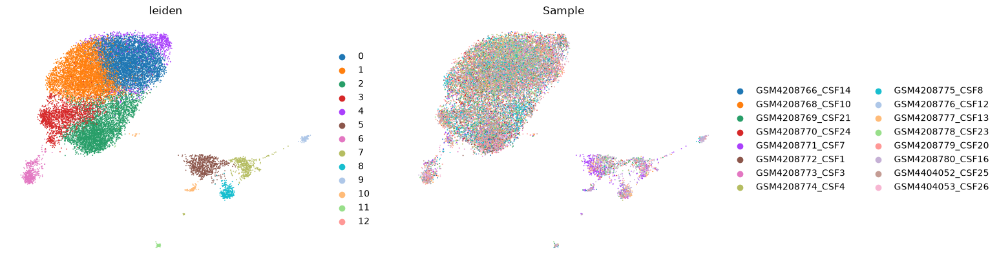

In [201]:
# filepath: /Users/prokash/DWCT/Thesis/Demo_PD_GSE141578/scRNA-seq_scanpy/single_cell_analysis_GSE141578.ipynb
# ...existing code...
adata = sc.read_h5ad("combined.h5ad").copy()
adata.var_names_make_unique()
sc.pp.filter_genes(adata, min_cells=10)
adata.layers["counts"] = adata.X.copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata

# 2) HVG with subset=False, then force marker retention (expanded for CSF)
marker_genes = [
    # Monocyte / Macrophage / CNS-resident myeloid
    "CD14", "LYZ", "FCGR3A", "MS4A7", "CD68", "CD163", "MRC1",
    "P2RY12", "TMEM119", "CX3CR1", "AIF1",

    # Dendritic cells
    "FCER1A", "CST3", "CLEC9A", "CD1C",

    # Cycling / proliferating
    "MKI67", "TOP2A",

    # T cells (general, CD4, CD8, naive/memory)
    "CD3D", "CD3E", "CD4", "IL7R", "CD8A", "CD8B", "CCR7", "SELL", "TCF7",

    # Treg
    "FOXP3", "IL2RA",

    # B cells
    "CD19", "MS4A1", "CD79A",

    # Plasma cells
    "SDC1", "PRDM1", "XBP1", "JCHAIN",

    # pDC
    "LILRA4", "IRF7", "GZMB",

    # NK
    "NKG7", "GNLY", "KLRD1", "NCAM1",

    # Neutrophil / granulocyte (rule in/out acute inflammation)
    "FCGR3B", "CSF3R", "S100A8", "S100A9",
]

# IMPORTANT: subset=False, then force marker retention
try:
    sc.pp.highly_variable_genes(
        adata,
        n_top_genes=2000,
        subset=False,
        layer="counts",
        flavor="seurat_v3",
        batch_key="Sample",
        span=0.6,  # slightly more stable than default
    )
except ValueError:
    # robust fallback if loess fails on per-batch fit
    sc.pp.highly_variable_genes(
        adata,
        n_top_genes=2000,
        subset=False,
        layer="counts",
        flavor="seurat_v3",
        batch_key=None,
        span=0.6,
    )

adata.var["highly_variable"] = adata.var["highly_variable"].fillna(False)

present_markers = [g for g in marker_genes if g in adata.var_names]
missing_markers = sorted(set(marker_genes) - set(present_markers))
adata.var.loc[present_markers, "highly_variable"] = True

print(f"Markers present: {len(present_markers)}/{len(marker_genes)}")
if missing_markers:
    print("Missing markers (not in var_names):", missing_markers)

# subset to expanded HVG set (HVG + forced markers)
adata = adata[:, adata.var["highly_variable"]].copy()
print("Post-subset shape:", adata.shape)

# 3) scVI setup + retrain on expanded gene set
covariates = [c for c in ["pct_counts_mt", "total_counts", "pct_counts_ribo"] if c in adata.obs.columns]


######################

scvi.model.SCVI.setup_anndata(
    adata,
    layer="counts",
    categorical_covariate_keys=["Sample"],
    continuous_covariate_keys=covariates
)

model = scvi.model.SCVI(adata, n_latent=30)

acc = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
model.train(accelerator=acc, devices=1, max_epochs=200)

adata.obsm["X_scVI"] = model.get_latent_representation()
adata.layers["scvi_normalized"] = model.get_normalized_expression(library_size=1e4)
sc.pp.neighbors(adata, use_rep="X_scVI", n_neighbors=15)
sc.tl.umap(adata, min_dist=0.3)
sc.tl.leiden(adata, resolution=1.0)
# verify marker availability for plotting
for g in ["CD4", "CD8A", "CD19"]:
    print(g, g in adata.var_names)

sc.pl.umap(adata, color=["leiden", "Sample"], frameon=False)
# Optional marker plot
# sc.pl.umap(adata, color=["CD4", "CD8A", "CD19"], layer="scvi_normalized", frameon=False)

adata.write_h5ad("integrated.h5ad")
model.save("model.model", overwrite=True)# ...existing code...

All Samples TOgether 

# Find markers/ label cell types

In [174]:
sc.tl.leiden(adata, resolution = 1)

/var/folders/ls/zbhsy_7j4q34qfbbpfg9xhg00000gn/T/ipykernel_79369/3164188017.py:1: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata, resolution = 1)


In [202]:
sc.tl.rank_genes_groups(adata, 'leiden')

In [ ]:
#sc.pl.rank_genes_groups(adata, n_genes=20, sharey=False)

In [203]:
markers = sc.get.rank_genes_groups_df(adata, None)
markers = markers[(markers.pvals_adj < 0.05) & (markers.logfoldchanges > .5)]
markers

,group,names,scores,logfoldchanges,pvals,pvals_adj
0,0,TCF7,30.575264,1.426089,1.072426e-193,2.382777e-191
1,0,LTB,29.416721,1.343297,9.949737e-181,1.820568e-178
2,0,IL7R,29.310482,0.994233,1.056889e-181,1.980458e-179
3,0,LEF1,28.975681,1.673810,1.846781e-174,3.156373e-172
4,0,MAL,27.679655,1.987942,1.418894e-159,2.121929e-157
...,...,...,...,...,...,...
186829,12,PGM2L1,2.337219,1.814207,2.308814e-02,4.700128e-02
186830,12,EHD1,2.330464,1.304779,2.346531e-02,4.774410e-02
186831,12,ARPC5,2.327388,0.696412,2.363404e-02,4.807484e-02
186832,12,TXN,2.326327,0.806057,2.369703e-02,4.819667e-02


In [204]:
markers_scvi = model.differential_expression(groupby = 'leiden')
markers_scvi

DE...: 100%|██████████| 13/13 [00:09<00:00,  1.38it/s]


,proba_m1,proba_m2,bayes_factor,scale1,scale2,raw_mean1,raw_mean2,non_zeros_proportion1,non_zeros_proportion2,raw_normalized_mean1,raw_normalized_mean2,comparison,group1,group2
AIRE,0.8542,0.1458,1.767929,3.368311e-05,0.000006,0.009086,0.000568,0.006186,0.000568,0.224328,0.019933,0 vs Rest,0,Rest
GTSCR1,0.8374,0.1626,1.639009,8.150261e-05,0.000015,0.013145,0.001632,0.010632,0.001561,0.509153,0.048834,0 vs Rest,0,Rest
FAM13A,0.8162,0.1838,1.490811,5.822876e-04,0.000097,0.098976,0.017031,0.064953,0.014973,5.210110,0.501582,0 vs Rest,0,Rest
CDO1,0.8058,0.1942,1.422947,5.757928e-05,0.000012,0.005026,0.000426,0.004060,0.000284,0.146555,0.009707,0 vs Rest,0,Rest
NEFL,0.8036,0.1964,1.408948,5.518349e-04,0.000121,0.071912,0.006316,0.045621,0.005180,1.732560,0.173160,0 vs Rest,0,Rest
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
AC099778.1,0.0984,0.9016,-2.215130,5.057643e-06,0.000047,0.000000,0.005258,0.000000,0.005102,0.000000,0.220661,12 vs Rest,12,Rest
ZNRF3,0.0966,0.9034,-2.235587,1.996387e-06,0.000018,0.000000,0.001093,0.000000,0.000989,0.000000,0.044958,12 vs Rest,12,Rest
SLC16A10,0.0918,0.9082,-2.291852,6.517815e-07,0.000028,0.000000,0.004789,0.000000,0.003956,0.000000,0.191013,12 vs Rest,12,Rest
LRRN3,0.0884,0.9116,-2.333329,2.021339e-06,0.000043,0.000000,0.005102,0.000000,0.003956,0.000000,0.140924,12 vs Rest,12,Rest


In [154]:
print(markers_scvi.columns.tolist())

['proba_m1', 'proba_m2', 'bayes_factor', 'scale1', 'scale2', 'raw_mean1', 'raw_mean2', 'non_zeros_proportion1', 'non_zeros_proportion2', 'raw_normalized_mean1', 'raw_normalized_mean2', 'comparison', 'group1', 'group2']


In [206]:
markers_scvi = model.differential_expression(
    groupby="leiden",       # or whatever your groupby was
    mode="change",
    fdr_target=0.05,
)
print(markers_scvi.columns.tolist())

DE...: 100%|██████████| 13/13 [00:10<00:00,  1.23it/s]
['proba_de', 'proba_not_de', 'bayes_factor', 'scale1', 'scale2', 'pseudocounts', 'delta', 'lfc_mean', 'lfc_median', 'lfc_std', 'lfc_min', 'lfc_max', 'raw_mean1', 'raw_mean2', 'non_zeros_proportion1', 'non_zeros_proportion2', 'raw_normalized_mean1', 'raw_normalized_mean2', 'is_de_fdr_0.05', 'comparison', 'group1', 'group2']


In [179]:
markers_scvi

,proba_de,proba_not_de,bayes_factor,scale1,scale2,pseudocounts,delta,lfc_mean,lfc_median,lfc_std,...,raw_mean1,raw_mean2,non_zeros_proportion1,non_zeros_proportion2,raw_normalized_mean1,raw_normalized_mean2,is_de_fdr_0.05,comparison,group1,group2
CD8B,0.9370,0.0630,2.699548,5.346155e-03,0.000678,0.000002,0.25,3.924600,3.969738,2.424135,...,1.566655,0.042038,0.603908,0.020986,49.156307,1.324391,False,0 vs Rest,0,Rest
NKG7,0.9272,0.0728,2.544453,1.440302e-02,0.002179,0.000002,0.25,4.818048,4.905429,3.046982,...,5.867542,0.759376,0.883218,0.150721,179.409653,21.111111,False,0 vs Rest,0,Rest
CCL5,0.9104,0.0896,2.318529,4.198052e-02,0.008892,0.000002,0.25,4.339979,4.079014,3.383374,...,12.803918,2.386003,0.979540,0.448005,402.749695,76.472153,False,0 vs Rest,0,Rest
KLRD1,0.9086,0.0914,2.296659,1.557327e-03,0.000394,0.000002,0.25,4.471082,4.591574,3.163812,...,0.342300,0.109890,0.198391,0.036674,10.890738,3.457127,False,0 vs Rest,0,Rest
TRGV8,0.8918,0.1082,2.109260,7.712031e-04,0.000112,0.000002,0.25,4.268198,4.230524,3.234907,...,0.133793,0.007442,0.083448,0.005833,4.311324,0.274986,False,0 vs Rest,0,Rest
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
AC110995.1,0.2084,0.7916,-1.334597,1.590817e-07,0.000002,0.000001,0.25,-0.684148,-0.434601,3.223220,...,0.000000,0.002078,0.000000,0.002026,0.000000,0.015023,False,13 vs Rest,13,Rest
CXCL12,0.2066,0.7934,-1.345543,1.119420e-07,0.000002,0.000001,0.25,-0.906704,-0.726043,3.612620,...,0.000000,0.001922,0.000000,0.001403,0.000000,0.011632,False,13 vs Rest,13,Rest
PCDHGC3,0.1974,0.8026,-1.402624,3.095927e-07,0.000001,0.000001,0.25,0.752663,0.940341,3.128850,...,0.000000,0.000623,0.000000,0.000519,0.000000,0.007158,False,13 vs Rest,13,Rest
SLC22A16,0.1894,0.8106,-1.453913,2.370679e-07,0.000002,0.000001,0.25,0.612037,0.951821,3.336882,...,0.000000,0.000675,0.000000,0.000623,0.000000,0.004317,False,13 vs Rest,13,Rest


In [207]:
markers_scvi = markers_scvi[(markers_scvi['is_de_fdr_0.05']) & (markers_scvi.lfc_mean > .5)]
markers_scvi

,proba_de,proba_not_de,bayes_factor,scale1,scale2,pseudocounts,delta,lfc_mean,lfc_median,lfc_std,...,raw_mean1,raw_mean2,non_zeros_proportion1,non_zeros_proportion2,raw_normalized_mean1,raw_normalized_mean2,is_de_fdr_0.05,comparison,group1,group2
CD14,0.9958,0.0042,5.468460,0.005818,0.000109,0.000002,0.25,8.129293,8.390154,2.454938,...,16.240097,0.112704,0.939974,0.027649,88.482246,0.932225,True,5 vs Rest,5,Rest
C5AR1,0.9940,0.0060,5.109976,0.002771,0.000048,0.000002,0.25,7.191916,7.347249,2.498731,...,4.489141,0.010010,0.789272,0.006655,26.746746,0.125682,True,5 vs Rest,5,Rest
C1QC,0.9938,0.0062,5.076985,0.011352,0.000188,0.000002,0.25,8.545194,8.806822,2.533735,...,21.019156,0.043826,0.882503,0.009902,111.008980,0.645749,True,5 vs Rest,5,Rest
C1QB,0.9924,0.0076,4.871977,0.011129,0.000171,0.000002,0.25,8.741303,8.954876,2.821442,...,17.578539,0.035440,0.871009,0.008603,90.835999,0.558886,True,5 vs Rest,5,Rest
SLC2A5,0.9922,0.0078,4.845800,0.000416,0.000008,0.000002,0.25,7.827795,7.999827,2.662309,...,0.763731,0.001840,0.418902,0.001515,4.429282,0.022769,True,5 vs Rest,5,Rest
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SH3BP4,0.9078,0.0922,2.287064,0.000060,0.000014,0.000001,0.25,3.969175,4.148592,2.691037,...,0.000000,0.007659,0.000000,0.007033,0.000000,0.061625,True,11 vs Rest,11,Rest
HOXA10,0.9072,0.0928,2.279916,0.000060,0.000012,0.000001,0.25,3.563951,3.615745,2.521208,...,0.000000,0.002970,0.000000,0.002449,0.000000,0.068121,True,11 vs Rest,11,Rest
MOB3B,0.9066,0.0934,2.272810,0.000083,0.000011,0.000001,0.25,4.104604,4.184932,2.763204,...,0.042254,0.007763,0.042254,0.007033,0.900774,0.067640,True,11 vs Rest,11,Rest
CYBB,0.9060,0.0940,2.265744,0.000633,0.000217,0.000001,0.25,4.022328,4.377415,2.553582,...,0.225352,0.192247,0.197183,0.065177,5.082525,1.500006,True,11 vs Rest,11,Rest


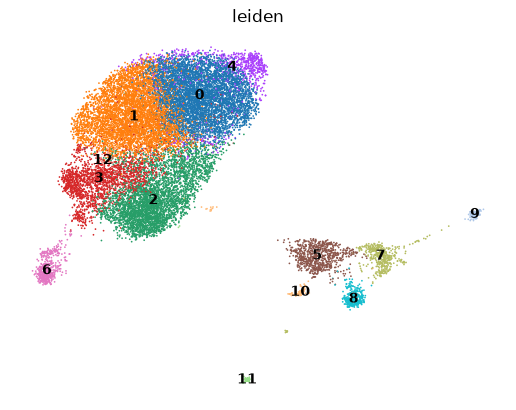

In [208]:
sc.pl.umap(adata, color = ['leiden'], frameon = False, legend_loc = "on data")

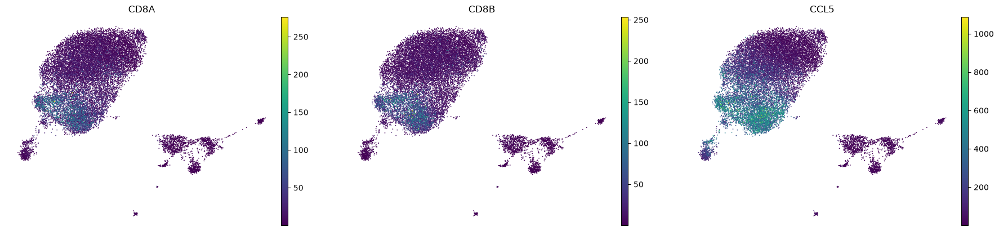

In [234]:
sc.pl.umap(adata, color = ["CD8A", "CD8B", "CCL5"], frameon = False, layer = 'scvi_normalized')
#, layer = 'scvi_normalized'

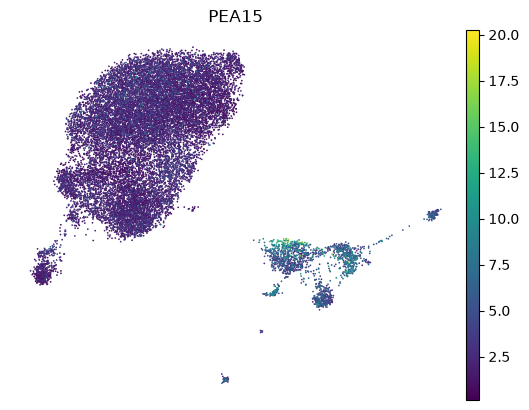

In [243]:
sc.pl.umap(adata, color = ["PEA15"], frameon = False, layer = 'scvi_normalized')
#, layer = 'scvi_normalized'

[OK] B cell: present=['CD19', 'MS4A1', 'CD79A'] | missing=['CD79B']
[OK] Naive B cell: present=['MS4A1', 'TCL1A', 'FCER2'] | missing=['IL4R']
[OK] Activated B cell: present=['CD83', 'CD86', 'MS4A1'] | missing=['CD69']
[OK] CD14+ monocyte: present=['CD14', 'LYZ', 'FCN1', 'S100A8', 'S100A9', 'VCAN'] | missing=[]
[OK] Monocyte: present=['CD14', 'FCGR3A', 'LYZ', 'MS4A7'] | missing=[]
[OK] Pan monocyte: present=['CD14', 'FCGR3A', 'LYZ', 'ITGAM'] | missing=[]
[OK] Macrophage: present=['CD68', 'CD163', 'MRC1', 'MSR1', 'APOE', 'C1QA', 'C1QB', 'C1QC'] | missing=[]
[OK] Marginal-associated macrophage: present=['CD163', 'MRC1', 'LYVE1', 'F13A1'] | missing=[]
[OK] Myeloid cell: present=['ITGAM', 'AIF1', 'CD68', 'LYZ'] | missing=[]
[OK] Dendritic cell: present=['FCER1A', 'CST3', 'CLEC9A', 'CD1C', 'HLA-DRA'] | missing=[]
[OK] Myeloid dendritic cell: present=['CD1C', 'FCER1A', 'ITGAX', 'CLEC10A'] | missing=[]
[OK] Plasmacytoid dendritic cell(pDC): present=['LILRA4', 'IRF7', 'GZMB', 'CLEC4C'] | missin

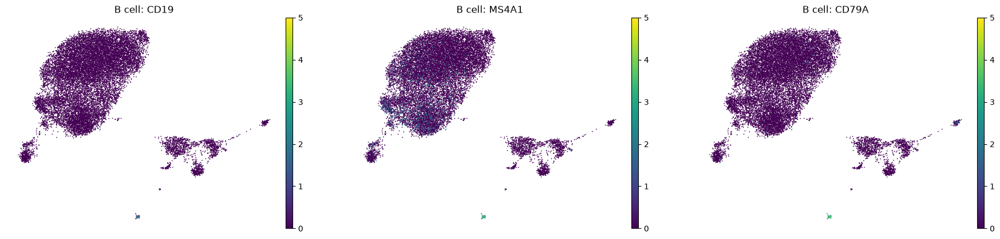

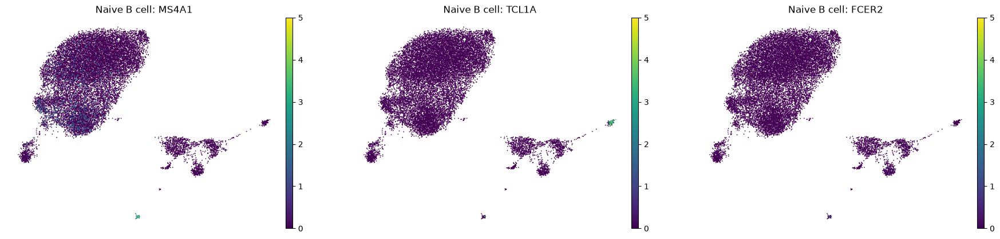

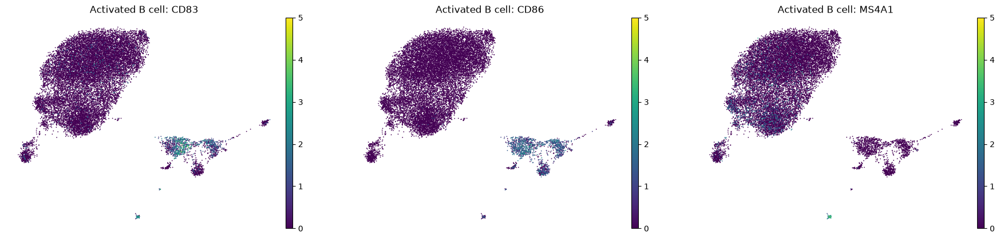

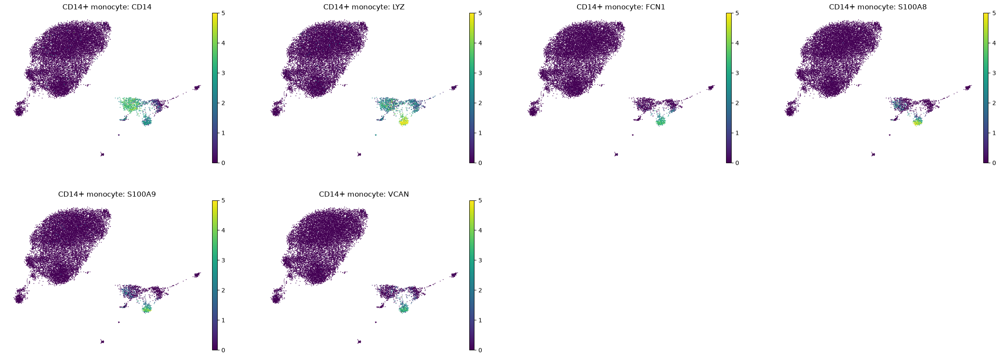

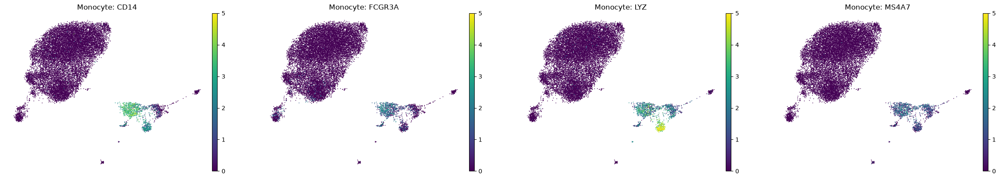

...

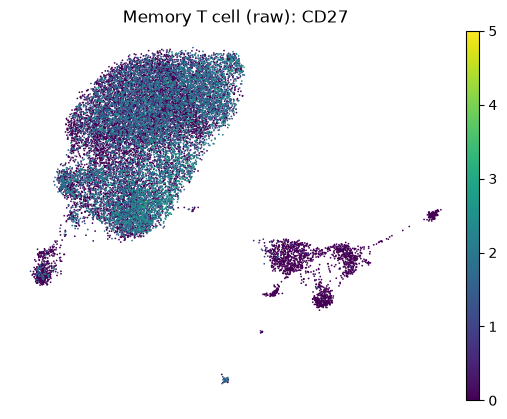

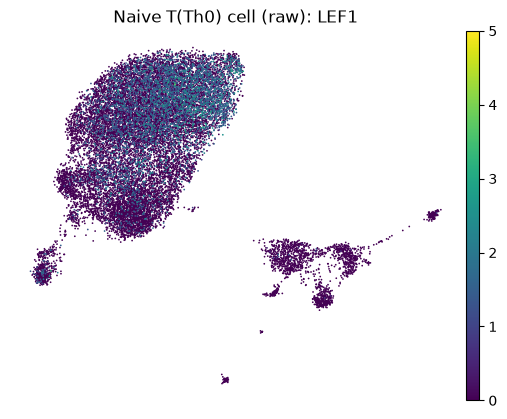

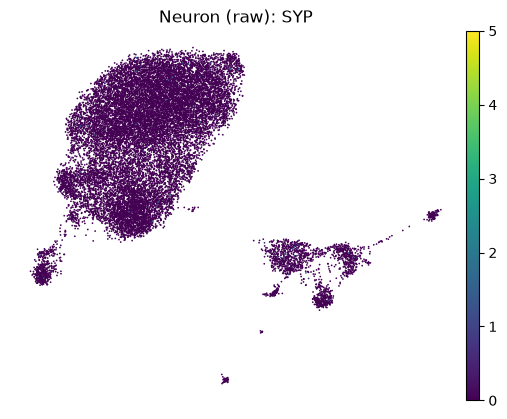

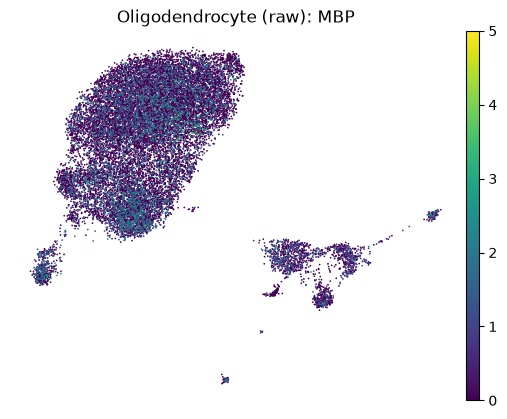

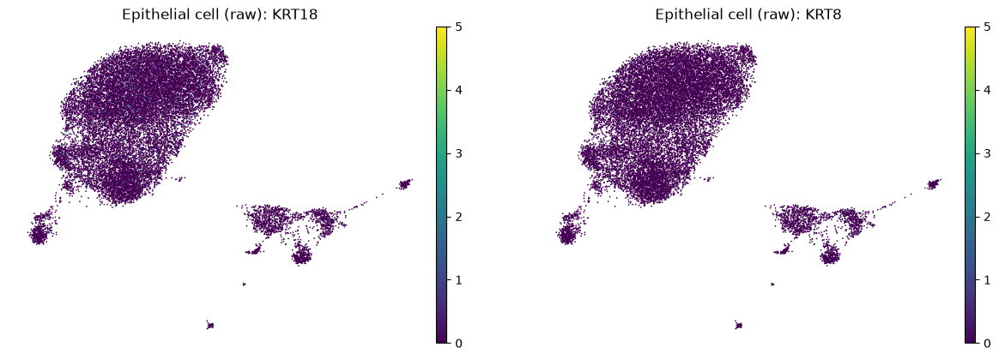

categories: 0, 1, 2, etc.
var_group_labels: B cell, Naive B cell, Activated B cell, etc.


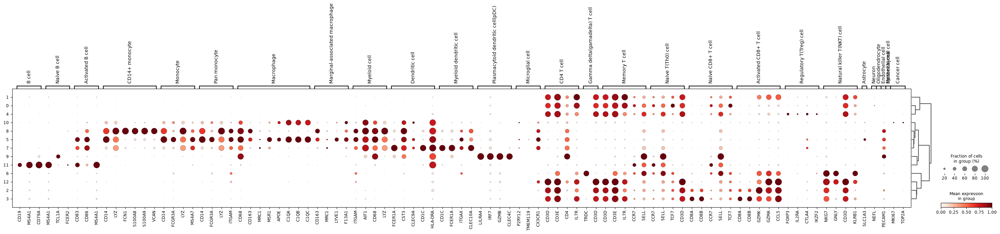

In [246]:
marker_dict = {
    "B cell": ["CD19", "MS4A1", "CD79A", "CD79B"],
    "Naive B cell": ["MS4A1", "TCL1A", "IL4R", "FCER2"],
    "Activated B cell": ["CD69", "CD83", "CD86", "MS4A1"],

    "CD14+ monocyte": ["CD14", "LYZ", "FCN1", "S100A8", "S100A9", "VCAN"],
    "Monocyte": ["CD14", "FCGR3A", "LYZ", "MS4A7"],
    "Pan monocyte": ["CD14", "FCGR3A", "LYZ", "ITGAM"],

    "Macrophage": ["CD68", "CD163", "MRC1", "MSR1", "APOE", "C1QA", "C1QB", "C1QC"],
    "Marginal-associated macrophage": ["CD163", "MRC1", "LYVE1", "F13A1"],

    "Myeloid cell": ["ITGAM", "AIF1", "CD68", "LYZ"],
    "Dendritic cell": ["FCER1A", "CST3", "CLEC9A", "CD1C", "HLA-DRA"],
    "Myeloid dendritic cell": ["CD1C", "FCER1A", "ITGAX", "CLEC10A"],
    "Plasmacytoid dendritic cell(pDC)": ["LILRA4", "IRF7", "GZMB", "CLEC4C"],

    "Microglial cell": ["P2RY12", "TMEM119", "CX3CR1", "SALL1"],

    "CD4 T cell": ["CD3D", "CD3E", "CD4", "IL7R"],
    "Gamma delta(gamadelta) T cell": ["TRDC", "TRGC1", "TRGC2", "CD3D"],
    "Memory T cell": ["CD3D", "CD3E", "IL7R", "CCR7", "SELL", "CD27"],
    "Naive T(Th0) cell": ["CCR7", "SELL", "TCF7", "LEF1", "CD3D"],
    "Naive CD8+ T cell": ["CD8A", "CD8B", "CCR7", "SELL", "TCF7"],
    "Activated CD8+ T cell": ["CD8A", "CD8B", "GZMK", "GZMA", "CCL5"],
    "Regulatory T(Treg) cell": ["FOXP3", "IL2RA", "CTLA4", "IKZF2"],
    "Natural killer T(NKT) cell": ["NKG7", "GNLY", "CD3D", "KLRB1"],

    "Astrocyte": ["GFAP", "AQP4", "SLC1A3", "ALDH1L1"],
    "Neuron": ["RBFOX3", "SYP", "MAP2", "NEFL"],
    "Oligodendrocyte": ["MBP", "PLP1", "MOG", "MOBP"],
    "Endothelial cell": ["PECAM1", "VWF", "CLDN5", "CDH5"],
    "Epithelial cell": ["EPCAM", "KRT18", "KRT8", "CDH1"],
    "Mesenchymal cell": ["COL1A1", "COL1A2", "PDGFRB", "DCN"],
    "Cancer cell": ["MKI67", "TOP2A"],
}

# 1) Check which markers survived HVG selection
present, missing = {}, {}
for cell_type, genes in marker_dict.items():
    present[cell_type] = [g for g in genes if g in adata.var_names]
    missing[cell_type] = [g for g in genes if g not in adata.var_names]

for cell_type in marker_dict:
    status = "OK" if present[cell_type] else "NONE PRESENT"
    print(f"[{status}] {cell_type}: present={present[cell_type]} | missing={missing[cell_type]}")

# 2) Plot present markers
for cell_type, genes in present.items():
    if genes:
        sc.pl.umap(
            adata, color=genes, frameon=False,
            # layer="scvi_normalized",
            vmax=5, title=[f"{cell_type}: {g}" for g in genes],
        )

# 3) Fallback: plot missing markers from raw/log-normalized (requires adata.raw set earlier)
for cell_type, genes in missing.items():
    genes_avail = [g for g in genes if g in adata.raw.var_names] if adata.raw is not None else []
    if genes_avail:
        sc.pl.umap(
            adata, color=genes_avail, frameon=False, use_raw=True,
            vmax=5, title=[f"{cell_type} (raw): {g}" for g in genes_avail],
        )

# 4) Dotplot summary across clusters — faster way to eyeball all cell types at once
sc.pl.dotplot(
    adata, present, groupby="leiden",
    # layer="scvi_normalized",
    standard_scale="var", dendrogram=True,
)

In [305]:
import scanpy as sc
import matplotlib.pyplot as plt

sc.settings.figdir = './figures/'

# The warning happens because `present` (var_group_labels) don't match the
# leiden cluster order — it's harmless, but you can suppress it by NOT passing
# dendrogram=True directly and instead computing/reordering separately if needed.
# Easiest fix: just leave dendrogram=True, the warning is only about group
# label alignment, not an actual error.

dp = sc.pl.dotplot(
    adata,
    present,
    groupby="leiden",
    standard_scale="var",
    dendrogram=True,
    figsize=(38, 8),          # widen substantially — more width = more room per label
    var_group_rotation=90,     # force rotation so labels don't run into each other
    show=False,
    return_fig=True,
)

# Increase spacing further and clean up label rendering
dp.style(cmap='Reds')
dp.savefig('./figures/dotplot_celltypes.pdf', bbox_inches='tight', dpi=300)
plt.close()

categories: 0, 1, 2, etc.
var_group_labels: B cell, Naive B cell, Activated B cell, etc.


In [239]:
markers[markers.names == 'TIGIT']

,group,names,scores,logfoldchanges,pvals,pvals_adj
31130,2,TIGIT,28.276615,2.257451,5.232822e-162,1.099812e-159
62220,4,TIGIT,10.355543,1.631136,1.033164e-23,3.181940e-22




# Monocytes (classical + non-classical, blood-derived/infiltrating)
"CD14", "LYZ", "FCN1", "VCAN", "S100A8", "S100A9",   # classical monocyte
"FCGR3A", "MS4A7",                                    # non-classical monocyte

# Macrophages (tissue/CNS-resident, differentiated)
"CD68", "CD163", "MRC1", "MSR1", "APOE", "C1QA", "C1QB", "C1QC",

# Microglia / CNS-resident myeloid (distinct from peripheral macrophages)
"P2RY12", "TMEM119", "CX3CR1", "SALL1",

# Pan-myeloid (not lineage-specific — useful as a general myeloid gate, not for subtyping)
"AIF1", "ITGAM",


marker_genes = [
    # Monocyte / Macrophage / CNS-resident myeloid
    "CD14", "LYZ", "FCGR3A", "MS4A7", "CD68", "CD163", "MRC1",
    "P2RY12", "TMEM119", "CX3CR1", "AIF1",

    # Dendritic cells
    "FCER1A", "CST3", "CLEC9A", "CD1C",

    # Cycling / proliferating
    "MKI67", "TOP2A",

    # T cells (general, CD4, CD8, naive/memory)
    "CD3D", "CD3E", "CD4", "IL7R", "CD8A", "CD8B", "CCR7", "SELL", "TCF7",

    # Treg
    "FOXP3", "IL2RA",

    # B cells
    "CD19", "MS4A1", "CD79A",

    # Plasma cells
    "SDC1", "PRDM1", "XBP1", "JCHAIN",

    # pDC
    "LILRA4", "IRF7", "GZMB",

    # NK
    "NKG7", "GNLY", "KLRD1", "NCAM1",

    # Neutrophil / granulocyte (rule in/out acute inflammation)
    "FCGR3B", "CSF3R", "S100A8", "S100A9",
]

In [247]:
cell_type = {"0":"CD4+ T-cell",
"1":"CD4+ T-cell",
"2":"CD8+ T-cell",
"3":"CD8+ T-cell",
"4":"CD4+ T-cell",
"5":"Macrophage",
"6":"NK cell",
"7":"DC",
"8":"Monocyte",
"9":"pDC",
"10":"Macrophage",
"11":"B-cell",
"12":"CD8+ T-cell"
}


In [250]:
adata.obs['cell type'] = adata.obs.leiden.map(cell_type)

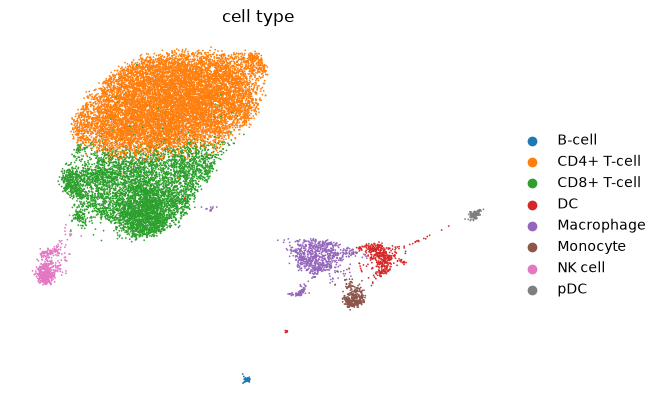

In [249]:
sc.pl.umap(adata, color = ['cell type'], frameon = False)

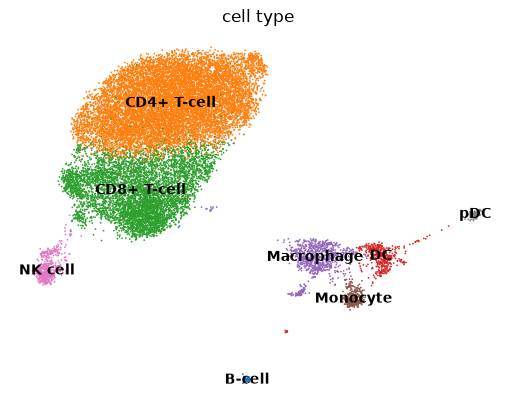

In [252]:
sc.pl.umap(adata, color = ['cell type'], frameon = False, legend_loc = "on data", legend_fontsize = 10)

/var/folders/ls/zbhsy_7j4q34qfbbpfg9xhg00000gn/T/ipykernel_79369/2004606138.py:5: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(


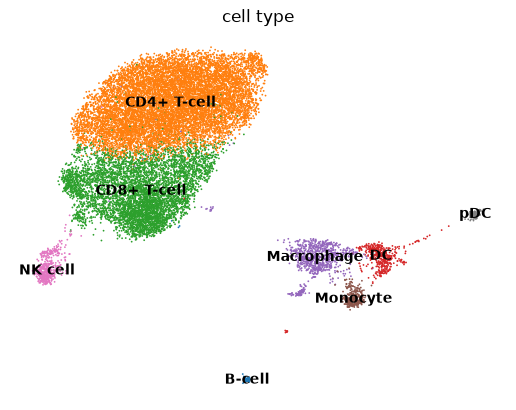

In [304]:
import scanpy as sc

sc.settings.figdir = './figures/'  # set output directory (optional)

sc.pl.umap(
    adata,
    color=['cell type'],
    frameon=False,
    legend_loc="on data",
    legend_fontsize=10,
    save='.pdf'  # will save as figures/umap.pdf
)

In [253]:
adata.obs

,Sample,doublet,n_genes,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,total_counts_ribo,pct_counts_ribo,batch,_scvi_batch,_scvi_labels,leiden,_scvi_raw_norm_scaling,cell type
AAACCTGAGACCCACC-1-GSM4208766_CSF14_filtered_feature_bc_matrix,GSM4208766_CSF14,False,739,739,1738.0,85.0,4.890679,579.0,33.314152,GSM4208766_CSF14_filtered_feature_bc_matrix,0,0,3,49.751244,CD8+ T-cell
AAACCTGAGAGGTTGC-1-GSM4208766_CSF14_filtered_feature_bc_matrix,GSM4208766_CSF14,False,692,692,2036.0,202.0,9.921414,876.0,43.025543,GSM4208766_CSF14_filtered_feature_bc_matrix,0,0,3,59.523811,CD8+ T-cell
AAACCTGAGCCACCTG-1-GSM4208766_CSF14_filtered_feature_bc_matrix,GSM4208766_CSF14,False,937,937,3015.0,144.0,4.776119,1460.0,48.424545,GSM4208766_CSF14_filtered_feature_bc_matrix,0,0,0,34.013603,CD4+ T-cell
AAACCTGAGCGCCTTG-1-GSM4208766_CSF14_filtered_feature_bc_matrix,GSM4208766_CSF14,False,832,832,3437.0,153.0,4.451557,1874.0,54.524296,GSM4208766_CSF14_filtered_feature_bc_matrix,0,0,0,26.525198,CD4+ T-cell
AAACCTGCAGATCTGT-1-GSM4208766_CSF14_filtered_feature_bc_matrix,GSM4208766_CSF14,False,735,735,1601.0,132.0,8.244846,525.0,32.792004,GSM4208766_CSF14_filtered_feature_bc_matrix,0,0,6,63.291142,NK cell
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTTACTGAGTGAACAT-1-GSM4404053_CSF26,GSM4404053_CSF26,False,2248,2248,8757.0,478.0,5.458490,3791.0,43.291080,GSM4404053_CSF26,0,0,0,10.504202,CD4+ T-cell
TTTATGCAGGGTTCCC-1-GSM4404053_CSF26,GSM4404053_CSF26,False,1376,1376,3519.0,314.0,8.922990,950.0,26.996305,GSM4404053_CSF26,0,0,1,29.325514,CD4+ T-cell
TTTATGCCACTATCTT-1-GSM4404053_CSF26,GSM4404053_CSF26,False,1965,1965,5896.0,380.0,6.445047,1848.0,31.343285,GSM4404053_CSF26,0,0,1,15.197569,CD4+ T-cell
TTTATGCTCAATACCG-1-GSM4404053_CSF26,GSM4404053_CSF26,False,2195,2195,6922.0,249.0,3.597226,2075.0,29.976887,GSM4404053_CSF26,0,0,3,12.820513,CD8+ T-cell


In [254]:
adata.uns['scvi_markers'] = markers_scvi
adata.uns['markers'] = markers

In [255]:
adata.write_h5ad('integrated.h5ad')

In [256]:
model.save('model.model')

ValueError: model.model already exists. Please provide another directory for saving.

# Analysis

In [ ]:
import scanpy as sc
import scvi
import seaborn as sns
import numpy as np
import pandas as pd

Global seed set to 0


## Counting cells

In [257]:
adata = sc.read_h5ad('integrated.h5ad')

In [258]:
adata.obs.Sample.unique().tolist()

['GSM4208766_CSF14',
 'GSM4208768_CSF10',
 'GSM4208769_CSF21',
 'GSM4208770_CSF24',
 'GSM4208771_CSF7',
 'GSM4208772_CSF1',
 'GSM4208773_CSF3',
 'GSM4208774_CSF4',
 'GSM4208775_CSF8',
 'GSM4208776_CSF12',
 'GSM4208777_CSF13',
 'GSM4208778_CSF23',
 'GSM4208779_CSF20',
 'GSM4208780_CSF16',
 'GSM4404052_CSF25',
 'GSM4404053_CSF26']

In [266]:
# Map GSM ID -> condition (PD/HC only — DLB and unlabeled samples excluded)
gsm_to_condition = {
    "GSM4208766": "PD",
    "GSM4208768": "PD",
    "GSM4208769": "PD",
    "GSM4208770": "PD",
    "GSM4208771": "PD",
    "GSM4208772": "HC",
    "GSM4208773": "HC",
    "GSM4208774": "HC",
    "GSM4208775": "HC",
    "GSM4208776": "HC",
    "GSM4208777": "HC",
    "GSM4208778": "HC",
    "GSM4208779": "HC",
    "GSM4208780": "HC",
    "GSM4404053": "PD",
    "GSM4404054": "PD",
    "GSM4404055": "HC",
    "GSM4404056": "PD",
    "GSM4404057": "PD",
    "GSM5579354": "HC",
    "GSM5579355": "HC",
    "GSM5579356": "PD",
    "GSM5579357": "HC",
    "GSM5579358": "PD",
    "GSM5579359": "PD",
    "GSM5579360": "PD",
    "GSM5579361": "PD",
    "GSM5579362": "PD",
    "GSM5579364": "HC",
    "GSM5579365": "HC",
    # excluded: GSM4404052 (DLB), GSM4404058 (DLB), GSM4404059 (unlabeled),
    # GSM5579363 (DLB), GSM5579366 (DLB)
}

def map_condition(x):
    gsm_id = x.split("_")[0]
    return gsm_to_condition.get(gsm_id, "unknown")

adata.obs["condition"] = adata.obs["Sample"].apply(map_condition)
print(adata.obs["condition"].value_counts())

# Keep only PD and HC
adata = adata[adata.obs["condition"].isin(["PD", "HC"])].copy()
print(adata.obs["condition"].value_counts())
print("Final shape:", adata.shape)

condition
HC         12437
PD          5809
unknown     1019
Name: count, dtype: int64
condition
HC    12437
PD     5809
Name: count, dtype: int64
Final shape: (18246, 2011)


In [269]:
adata.obs['condition'] = adata.obs.Sample.map(map_condition)
adata.obs

,Sample,doublet,n_genes,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,total_counts_ribo,pct_counts_ribo,batch,_scvi_batch,_scvi_labels,leiden,_scvi_raw_norm_scaling,cell type,condition
AAACCTGAGACCCACC-1-GSM4208766_CSF14_filtered_feature_bc_matrix,GSM4208766_CSF14,False,739,739,1738.0,85.0,4.890679,579.0,33.314152,GSM4208766_CSF14_filtered_feature_bc_matrix,0,0,3,49.751244,CD8+ T-cell,PD
AAACCTGAGAGGTTGC-1-GSM4208766_CSF14_filtered_feature_bc_matrix,GSM4208766_CSF14,False,692,692,2036.0,202.0,9.921414,876.0,43.025543,GSM4208766_CSF14_filtered_feature_bc_matrix,0,0,3,59.523811,CD8+ T-cell,PD
AAACCTGAGCCACCTG-1-GSM4208766_CSF14_filtered_feature_bc_matrix,GSM4208766_CSF14,False,937,937,3015.0,144.0,4.776119,1460.0,48.424545,GSM4208766_CSF14_filtered_feature_bc_matrix,0,0,0,34.013603,CD4+ T-cell,PD
AAACCTGAGCGCCTTG-1-GSM4208766_CSF14_filtered_feature_bc_matrix,GSM4208766_CSF14,False,832,832,3437.0,153.0,4.451557,1874.0,54.524296,GSM4208766_CSF14_filtered_feature_bc_matrix,0,0,0,26.525198,CD4+ T-cell,PD
AAACCTGCAGATCTGT-1-GSM4208766_CSF14_filtered_feature_bc_matrix,GSM4208766_CSF14,False,735,735,1601.0,132.0,8.244846,525.0,32.792004,GSM4208766_CSF14_filtered_feature_bc_matrix,0,0,6,63.291142,NK cell,PD
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTTACTGAGTGAACAT-1-GSM4404053_CSF26,GSM4404053_CSF26,False,2248,2248,8757.0,478.0,5.458490,3791.0,43.291080,GSM4404053_CSF26,0,0,0,10.504202,CD4+ T-cell,PD
TTTATGCAGGGTTCCC-1-GSM4404053_CSF26,GSM4404053_CSF26,False,1376,1376,3519.0,314.0,8.922990,950.0,26.996305,GSM4404053_CSF26,0,0,1,29.325514,CD4+ T-cell,PD
TTTATGCCACTATCTT-1-GSM4404053_CSF26,GSM4404053_CSF26,False,1965,1965,5896.0,380.0,6.445047,1848.0,31.343285,GSM4404053_CSF26,0,0,1,15.197569,CD4+ T-cell,PD
TTTATGCTCAATACCG-1-GSM4404053_CSF26,GSM4404053_CSF26,False,2195,2195,6922.0,249.0,3.597226,2075.0,29.976887,GSM4404053_CSF26,0,0,3,12.820513,CD8+ T-cell,PD


In [270]:
num_tot_cells = adata.obs.groupby(['Sample']).count()
num_tot_cells = dict(zip(num_tot_cells.index, num_tot_cells.doublet))
num_tot_cells

{'GSM4208766_CSF14': 1475,
 'GSM4208768_CSF10': 546,
 'GSM4208769_CSF21': 1221,
 'GSM4208770_CSF24': 1101,
 'GSM4208771_CSF7': 1253,
 'GSM4208772_CSF1': 1348,
 'GSM4208773_CSF3': 1548,
 'GSM4208774_CSF4': 1898,
 'GSM4208775_CSF8': 2026,
 'GSM4208776_CSF12': 303,
 'GSM4208777_CSF13': 971,
 'GSM4208778_CSF23': 1309,
 'GSM4208779_CSF20': 1461,
 'GSM4208780_CSF16': 1573,
 'GSM4404053_CSF26': 213}

In [271]:
cell_type_counts = adata.obs.groupby(['Sample', 'condition', 'cell type']).count()
cell_type_counts = cell_type_counts[cell_type_counts.sum(axis = 1) > 0].reset_index()
cell_type_counts = cell_type_counts[cell_type_counts.columns[0:4]]
cell_type_counts

,Sample,condition,cell type,doublet
0,GSM4208766_CSF14,PD,B-cell,4
1,GSM4208766_CSF14,PD,CD4+ T-cell,899
2,GSM4208766_CSF14,PD,CD8+ T-cell,465
3,GSM4208766_CSF14,PD,DC,19
4,GSM4208766_CSF14,PD,Macrophage,34
...,...,...,...,...
109,GSM4404053_CSF26,PD,CD4+ T-cell,110
110,GSM4404053_CSF26,PD,CD8+ T-cell,47
111,GSM4404053_CSF26,PD,DC,2
112,GSM4404053_CSF26,PD,Macrophage,10


In [272]:
cell_type_counts['total_cells'] = cell_type_counts.Sample.map(num_tot_cells).astype(int)

cell_type_counts['frequency'] = cell_type_counts.doublet / cell_type_counts.total_cells

cell_type_counts

,Sample,condition,cell type,doublet,total_cells,frequency
0,GSM4208766_CSF14,PD,B-cell,4,1475,0.002712
1,GSM4208766_CSF14,PD,CD4+ T-cell,899,1475,0.609492
2,GSM4208766_CSF14,PD,CD8+ T-cell,465,1475,0.315254
3,GSM4208766_CSF14,PD,DC,19,1475,0.012881
4,GSM4208766_CSF14,PD,Macrophage,34,1475,0.023051
...,...,...,...,...,...,...
109,GSM4404053_CSF26,PD,CD4+ T-cell,110,213,0.516432
110,GSM4404053_CSF26,PD,CD8+ T-cell,47,213,0.220657
111,GSM4404053_CSF26,PD,DC,2,213,0.009390
112,GSM4404053_CSF26,PD,Macrophage,10,213,0.046948


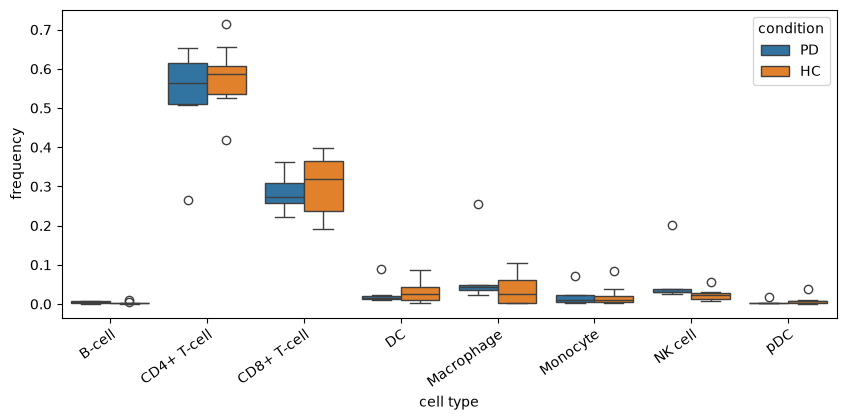

In [273]:
import matplotlib.pyplot as plt

plt.figure(figsize = (10,4))

ax = sns.boxplot(data = cell_type_counts, x = 'cell type', y = 'frequency', hue = 'condition')

plt.xticks(rotation = 35, rotation_mode = 'anchor', ha = 'right')

plt.show()


## DE

In [288]:
subset = adata[adata.obs['cell type'].isin(['CD4+ T-cell', 'CD8+ T-cell'])].copy()

In [ ]:
#two options: SCVI or diffxpy

In [276]:
!pip install diffxpy

  Using cached toolz-1.1.0-py3-none-any.whl.metadata (5.1 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 9.8 MB/s  0:00:00
Using cached toolz-1.1.0-py3-none-any.whl (58 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [diffxpy]m5/8 [dask]


In [277]:
import diffxpy.api as de

In [289]:
subset.X = subset.X.toarray()

In [290]:
len(subset.var)

2011

In [291]:
subset

AnnData object with n_obs × n_vars = 15901 × 2011
    obs: 'Sample', 'doublet', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'batch', '_scvi_batch', '_scvi_labels', 'leiden', '_scvi_raw_norm_scaling', 'cell type', 'condition'
    var: 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: 'Sample_colors', '_scvi_manager_uuid', '_scvi_uuid', 'cell type_colors', 'dendrogram_leiden', 'hvg', 'leiden', 'leiden_colors', 'log1p', 'markers', 'neighbors', 'pca', 'rank_genes_groups', 'scvi_markers', 'umap'
    obsm: 'X_pca', 'X_scVI', 'X_umap', '_scvi_extra_categorical_covs', '_scvi_extra_continuous_covs'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'
    layers: 'counts', 'scvi_normalized', None (.X)

In [292]:
sc.pp.filter_genes(subset, min_cells=10)

In [293]:
len(subset.var)

1594

In [294]:
subset.obs = subset.obs.rename(columns = {'cell type':'cell_type'})

In [ ]:
#subset = subset.raw.to_adata() #need to run this if you scaled/regress your data and have negative numbers


In [295]:
subset.obs

,Sample,doublet,n_genes,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,total_counts_ribo,pct_counts_ribo,batch,_scvi_batch,_scvi_labels,leiden,_scvi_raw_norm_scaling,cell_type,condition
AAACCTGAGACCCACC-1-GSM4208766_CSF14_filtered_feature_bc_matrix,GSM4208766_CSF14,False,739,739,1738.0,85.0,4.890679,579.0,33.314152,GSM4208766_CSF14_filtered_feature_bc_matrix,0,0,3,49.751244,CD8+ T-cell,PD
AAACCTGAGAGGTTGC-1-GSM4208766_CSF14_filtered_feature_bc_matrix,GSM4208766_CSF14,False,692,692,2036.0,202.0,9.921414,876.0,43.025543,GSM4208766_CSF14_filtered_feature_bc_matrix,0,0,3,59.523811,CD8+ T-cell,PD
AAACCTGAGCCACCTG-1-GSM4208766_CSF14_filtered_feature_bc_matrix,GSM4208766_CSF14,False,937,937,3015.0,144.0,4.776119,1460.0,48.424545,GSM4208766_CSF14_filtered_feature_bc_matrix,0,0,0,34.013603,CD4+ T-cell,PD
AAACCTGAGCGCCTTG-1-GSM4208766_CSF14_filtered_feature_bc_matrix,GSM4208766_CSF14,False,832,832,3437.0,153.0,4.451557,1874.0,54.524296,GSM4208766_CSF14_filtered_feature_bc_matrix,0,0,0,26.525198,CD4+ T-cell,PD
AAACCTGGTCTCATCC-1-GSM4208766_CSF14_filtered_feature_bc_matrix,GSM4208766_CSF14,False,898,898,2600.0,128.0,4.923077,1092.0,42.000000,GSM4208766_CSF14_filtered_feature_bc_matrix,0,0,0,41.322311,CD4+ T-cell,PD
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTTACTGAGTGAACAT-1-GSM4404053_CSF26,GSM4404053_CSF26,False,2248,2248,8757.0,478.0,5.458490,3791.0,43.291080,GSM4404053_CSF26,0,0,0,10.504202,CD4+ T-cell,PD
TTTATGCAGGGTTCCC-1-GSM4404053_CSF26,GSM4404053_CSF26,False,1376,1376,3519.0,314.0,8.922990,950.0,26.996305,GSM4404053_CSF26,0,0,1,29.325514,CD4+ T-cell,PD
TTTATGCCACTATCTT-1-GSM4404053_CSF26,GSM4404053_CSF26,False,1965,1965,5896.0,380.0,6.445047,1848.0,31.343285,GSM4404053_CSF26,0,0,1,15.197569,CD4+ T-cell,PD
TTTATGCTCAATACCG-1-GSM4404053_CSF26,GSM4404053_CSF26,False,2195,2195,6922.0,249.0,3.597226,2075.0,29.976887,GSM4404053_CSF26,0,0,3,12.820513,CD8+ T-cell,PD


In [297]:
!pip install "dask<2023.1" "batchglm==0.7.4" diffxpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 7.4 MB/s  0:00:00 eta 0:00:01
  Attempting uninstall: dask
    Found existing installation: dask 2026.7.1
    Uninstalling dask-2026.7.1:
      Successfully uninstalled dask-2026.7.1


In [302]:
import numpy, dask, batchglm
print("numpy:", numpy.__version__)
print("dask:", dask.__version__)
print("batchglm imported OK")

numpy: 2.5.2
dask: 2026.7.1
batchglm imported OK


In [303]:
#if want to test between covid/non covid
# res = de.test.wald(data=subset,
#              formula_loc= '~ 1 + condition',
#              factor_loc_totest='condition'
#                   )


res = de.test.wald(data=subset,
             formula_loc= '~ 1 + cell_type',
             factor_loc_totest='cell_type'
                  )

training location model: False
training scale model: True
iter   0: ll=247029813.519173
iter   1: ll=247029813.519173, converged: 0.00% (loc: 100.00%, scale update: False), in 0.00sec
Fitting 1594 dispersion models: (progress not available with multiprocessing)

/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/anndata/_core/anndata.py:20: UserWarning: A NumPy version >=2.0.0 and <2.8.0 is required for this version of SciPy (detected version 1.26.4)
  from scipy.sparse import issparse
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/anndata/_core/anndata.py:20: UserWarning: A NumPy version >=2.0.0 and <2.8.0 is required for this version of SciPy (detected version 1.26.4)
  from scipy.sparse import issparse
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/anndata/_core/anndata.py:20: UserWarning: A NumPy version >=2.0.0 and <2.8.0 is required for this version of SciPy (detected version 1.26.4)
  from scipy.sparse import issparse
/Users/prokash/.venvs/jupyter-base/lib/python3.14/site-packages/scipy/sparse/_sputils.py:17: FutureWarning: In the future `np.long` will be defined as the corresponding NumPy scalar.
  np.uintc, np.long, np.ulong, np.longlong, np.ulonglong,
/Users/prokash/.venvs/jupyter-base/l

KeyboardInterrupt: 

In [ ]:
dedf = res.summary().sort_values('log2fc', ascending = False).reset_index(drop = True)
dedf

,gene,pval,qval,log2fc,mean,zero_mean,grad,coef_mle,coef_sd,ll
0,AC018359.1,0.000000e+00,0.000000e+00,283.913085,0.014774,False,1.471862e-02,283.913085,2.222759e-162,-2038.835727
1,COL11A1,0.000000e+00,0.000000e+00,283.913085,0.018803,False,1.816848e-02,283.913085,2.222759e-162,-2527.167941
2,AC079015.1,0.000000e+00,0.000000e+00,283.913085,0.020568,False,2.069841e-02,283.913085,2.222759e-162,-2861.828587
3,LINC01584,0.000000e+00,0.000000e+00,283.913085,0.034148,False,3.242799e-02,283.913085,2.222759e-162,-4523.540856
4,AL358335.2,0.000000e+00,0.000000e+00,283.913085,0.013112,False,1.241874e-02,283.913085,2.222759e-162,-1731.587302
...,...,...,...,...,...,...,...,...,...,...
12700,AC095050.1,1.162741e-83,1.762842e-82,-6.081826,0.155194,False,1.322622e-08,-6.081826,3.138373e-01,-5165.938157
12701,SEMA3E,0.000000e+00,0.000000e+00,-297.776029,0.089118,False,1.486194e-08,-297.776029,2.222759e-162,-3373.322329
12702,LINC02814,0.000000e+00,0.000000e+00,-297.776029,0.018353,False,4.406181e-10,-297.776029,2.222759e-162,-962.055118
12703,AL807742.1,0.000000e+00,0.000000e+00,-297.776029,0.023837,False,5.994505e-10,-297.776029,2.222759e-162,-1201.275625


In [ ]:
subset.obs.cell_type.unique()

['AT1', 'AT2']
Categories (2, object): ['AT1', 'AT2']

In [ ]:
most_up = dedf.iloc[0].gene
i = np.where(subset.var_names == most_up)[0][0]

a = subset[subset.obs.cell_type == 'AT1'].X[:, i]
b = subset[subset.obs.cell_type == 'AT2'].X[:, i]
print(f"{most_up} expression:")
print(f"AT1: {a.mean()}")
print(f"AT2: {b.mean()}")


AC018359.1 expression:
AT1: 0.0
AT2: 0.02354462631046772


In [ ]:
dedf['log2fc'] = dedf['log2fc']*-1
dedf = dedf.sort_values('log2fc', ascending = False).reset_index(drop = True)
dedf

,gene,pval,qval,log2fc,mean,zero_mean,grad,coef_mle,coef_sd,ll
0,AC105914.2,0.000000e+00,0.000000e+00,297.776029,0.014490,False,1.973365e-11,-297.776029,2.222759e-162,-794.845097
1,AL807742.1,0.000000e+00,0.000000e+00,297.776029,0.023837,False,5.994505e-10,-297.776029,2.222759e-162,-1201.275625
2,LINC02814,0.000000e+00,0.000000e+00,297.776029,0.018353,False,4.406181e-10,-297.776029,2.222759e-162,-962.055118
3,SEMA3E,0.000000e+00,0.000000e+00,297.776029,0.089118,False,1.486194e-08,-297.776029,2.222759e-162,-3373.322329
4,AC095050.1,1.162741e-83,1.762842e-82,6.081826,0.155194,False,1.322622e-08,-6.081826,3.138373e-01,-5165.938157
...,...,...,...,...,...,...,...,...,...,...
12700,AC079015.1,0.000000e+00,0.000000e+00,-283.913085,0.020568,False,2.069841e-02,283.913085,2.222759e-162,-2861.828587
12701,COL11A1,0.000000e+00,0.000000e+00,-283.913085,0.018803,False,1.816848e-02,283.913085,2.222759e-162,-2527.167941
12702,AL358335.2,0.000000e+00,0.000000e+00,-283.913085,0.013112,False,1.241874e-02,283.913085,2.222759e-162,-1731.587302
12703,LGI3,0.000000e+00,0.000000e+00,-283.913085,0.021436,False,2.092837e-02,283.913085,2.222759e-162,-2906.469822


In [ ]:
dedf = dedf[(dedf.qval < 0.05) & (abs(dedf.log2fc) > .5)]
dedf

,gene,pval,qval,log2fc,mean,zero_mean,grad,coef_mle,coef_sd,ll
0,AC105914.2,0.000000e+00,0.000000e+00,297.776029,0.014490,False,1.973365e-11,-297.776029,2.222759e-162,-794.845097
1,AL807742.1,0.000000e+00,0.000000e+00,297.776029,0.023837,False,5.994505e-10,-297.776029,2.222759e-162,-1201.275625
2,LINC02814,0.000000e+00,0.000000e+00,297.776029,0.018353,False,4.406181e-10,-297.776029,2.222759e-162,-962.055118
3,SEMA3E,0.000000e+00,0.000000e+00,297.776029,0.089118,False,1.486194e-08,-297.776029,2.222759e-162,-3373.322329
4,AC095050.1,1.162741e-83,1.762842e-82,6.081826,0.155194,False,1.322622e-08,-6.081826,3.138373e-01,-5165.938157
...,...,...,...,...,...,...,...,...,...,...
12700,AC079015.1,0.000000e+00,0.000000e+00,-283.913085,0.020568,False,2.069841e-02,283.913085,2.222759e-162,-2861.828587
12701,COL11A1,0.000000e+00,0.000000e+00,-283.913085,0.018803,False,1.816848e-02,283.913085,2.222759e-162,-2527.167941
12702,AL358335.2,0.000000e+00,0.000000e+00,-283.913085,0.013112,False,1.241874e-02,283.913085,2.222759e-162,-1731.587302
12703,LGI3,0.000000e+00,0.000000e+00,-283.913085,0.021436,False,2.092837e-02,283.913085,2.222759e-162,-2906.469822


In [ ]:
dedf = dedf[dedf['mean'] > 0.15]
dedf

,gene,pval,qval,log2fc,mean,zero_mean,grad,coef_mle,coef_sd,ll
4,AC095050.1,1.162741e-83,1.762842e-82,6.081826,0.155194,False,1.322622e-08,-6.081826,0.313837,-5165.938157
7,NCKAP5-AS2,2.313156e-168,6.619064e-167,5.859465,0.273974,False,1.930704e-09,-5.859465,0.211864,-7500.659488
9,RGCC,5.424794e-217,2.051250e-215,5.321312,0.255538,False,1.417977e-09,-5.321312,0.169243,-7263.808007
13,AL355499.1,0.000000e+00,0.000000e+00,5.223264,0.561619,False,1.075236e-09,-5.223264,0.107791,-11323.233400
17,AC022325.2,0.000000e+00,0.000000e+00,4.943113,0.499731,False,9.288125e-11,-4.943113,0.100757,-10848.540222
...,...,...,...,...,...,...,...,...,...,...
12685,HHIP,3.449008e-86,5.389871e-85,-5.207289,0.260891,False,1.157253e-10,5.207289,0.264649,-8370.357374
12689,AC096531.2,5.381522e-201,1.899229e-199,-5.387216,0.679850,False,1.012193e-10,5.387216,0.178096,-15810.527889
12691,LINC01811,2.052466e-62,2.464705e-61,-5.463941,0.219332,False,3.030598e-08,5.463941,0.327708,-7109.339800
12695,PTGFR,3.909067e-69,5.104285e-68,-5.683710,0.276595,False,9.620706e-10,5.683710,0.323419,-9091.070476


In [ ]:
genes_to_show = dedf[-25:].gene.tolist() + dedf[:25].gene.tolist() #top 25 and bottom 25 from sorted df

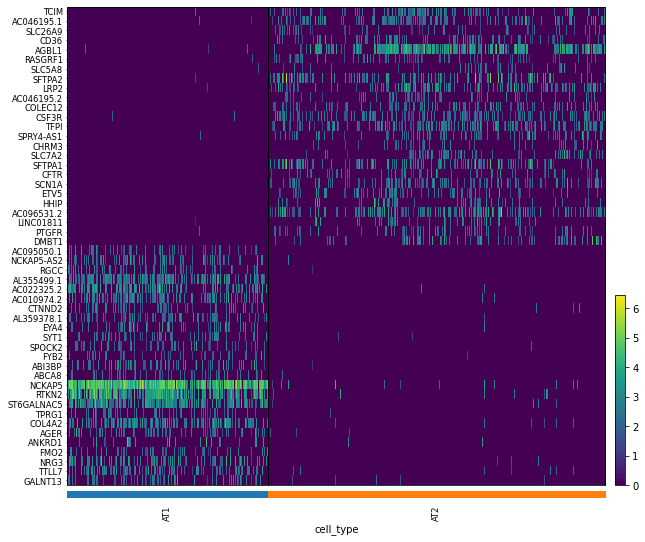

In [ ]:
sc.pl.heatmap(subset, genes_to_show, groupby='cell_type', swap_axes=True)

In [ ]:
#DE with scvi

In [ ]:
model  = scvi.model.SCVI.load('model.model', adata)

INFO     File model.model/model.pt already downloaded                                        
adfsdfsdf
adfsdfsdf
adfsdfsdf
adfsdfsdf


In [ ]:
model

SCVI Model with the following params: 
n_hidden: 128, n_latent: 10, n_layers: 1, dropout_rate: 0.1, dispersion: gene, 
gene_likelihood: zinb, latent_distribution: normal
Training status: Trained

In [ ]:
scvi_de = model.differential_expression(
    idx1 = [adata.obs['cell type'] == 'AT1'],
    idx2 = [adata.obs['cell type'] == 'AT2']
    )

#any set of cells vs any set of cells
# scvi_de = model.differential_expression(
#     idx1 = [(adata.obs['cell type'].isin(['AT1', 'AT2'])) & (adata.obs.condition == 'COVID19')],
#     idx2 = [(adata.obs['cell type'].isin(['AT1', 'AT2'])) & (adata.obs.condition == 'control')]
#     )

DE...: 100%|██████████████████████████████████████| 1/1 [00:05<00:00,  5.46s/it]


In [ ]:
scvi_de

,proba_de,proba_not_de,bayes_factor,scale1,scale2,pseudocounts,delta,lfc_mean,lfc_median,lfc_std,lfc_min,lfc_max,raw_mean1,raw_mean2,non_zeros_proportion1,non_zeros_proportion2,raw_normalized_mean1,raw_normalized_mean2,is_de_fdr_0.05
DMBT1,0.9982,0.0018,6.318161,0.000004,4.513010e-04,0.0,0.25,-8.036115,-8.050153,3.126623,-17.124987,3.295891,0.000772,0.652699,0.000772,0.216806,0.004793,4.311816,True
WNT3A,0.9982,0.0018,6.318161,0.000082,1.773648e-06,0.0,0.25,6.408226,6.574142,2.301937,-2.184126,12.912475,0.115296,0.002108,0.098935,0.002108,0.817271,0.011588,True
AL355499.1,0.9980,0.0020,6.212601,0.000897,1.932020e-05,0.0,0.25,6.727534,6.930730,2.437289,-4.308558,14.008843,1.323336,0.008430,0.556104,0.004307,9.164151,0.028797,True
AC105914.2,0.9980,0.0020,6.212601,0.000014,1.589177e-07,0.0,0.25,6.372631,6.558585,2.219326,-2.153578,13.018692,0.019293,0.000000,0.018521,0.000000,0.148828,0.000000,True
TTLL7,0.9978,0.0022,6.117091,0.000360,2.404536e-05,0.0,0.25,4.069274,4.183637,1.283290,-1.938815,8.505215,0.559035,0.014387,0.354839,0.012554,4.009957,0.078429,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ARID2,0.3742,0.6258,-0.514240,0.000191,1.930834e-04,0.0,0.25,-0.014206,-0.013475,0.281394,-1.349488,1.011988,0.314557,0.324474,0.246643,0.253276,2.150865,2.113666,False
SENP6,0.3694,0.6306,-0.534792,0.000317,3.276030e-04,0.0,0.25,-0.054595,-0.034585,0.296423,-2.012589,1.205351,0.472144,0.538348,0.342028,0.371667,3.274352,3.527349,False
TRIP12,0.3604,0.6396,-0.573628,0.000196,2.121055e-04,0.0,0.25,-0.115991,-0.112569,0.259490,-1.197508,0.898626,0.321503,0.357280,0.256521,0.275818,2.170178,2.294853,False
SNW1,0.3594,0.6406,-0.577969,0.000041,4.309067e-05,0.0,0.25,-0.053936,-0.056183,0.267382,-1.019018,1.037309,0.063127,0.067443,0.060040,0.062952,0.438933,0.430199,False


In [ ]:
scvi_de = scvi_de[(scvi_de['is_de_fdr_0.05']) & (abs(scvi_de.lfc_mean) > .5)]
scvi_de = scvi_de.sort_values('lfc_mean')
scvi_de

,proba_de,proba_not_de,bayes_factor,scale1,scale2,pseudocounts,delta,lfc_mean,lfc_median,lfc_std,lfc_min,lfc_max,raw_mean1,raw_mean2,non_zeros_proportion1,non_zeros_proportion2,raw_normalized_mean1,raw_normalized_mean2,is_de_fdr_0.05
AC096531.2,0.9972,0.0028,5.875328,5.579448e-06,7.901783e-04,0.0,0.25,-8.643203,-9.043480,2.897235,-15.816298,3.244891,0.002933,0.997323,0.002778,0.408870,0.021904,6.957193,True
DMBT1,0.9982,0.0018,6.318161,3.602960e-06,4.513010e-04,0.0,0.25,-8.036115,-8.050153,3.126623,-17.124987,3.295891,0.000772,0.652699,0.000772,0.216806,0.004793,4.311816,True
CHI3L1,0.9942,0.0058,5.144079,6.746318e-07,3.074286e-05,0.0,0.25,-7.818566,-8.191303,3.449313,-16.311127,6.329714,0.000309,0.052232,0.000309,0.038578,0.001423,0.316771,True
SLC26A9,0.9972,0.0028,5.875328,4.452664e-06,1.697237e-04,0.0,0.25,-7.314053,-7.620886,2.954999,-14.140657,4.266300,0.003241,0.217261,0.002933,0.163750,0.021548,1.435716,True
TMEM163,0.9972,0.0028,5.875328,3.144645e-05,1.178261e-03,0.0,0.25,-7.183823,-7.374844,2.857690,-14.284339,3.777314,0.041827,1.918456,0.028245,0.650692,0.241671,13.034749,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
NCKAP5,0.9972,0.0028,5.875328,7.764196e-03,1.420981e-04,0.0,0.25,6.607409,6.853317,2.110482,-2.175611,14.047405,12.053660,0.071200,0.909400,0.031889,85.427116,0.441436,True
ROR1-AS1,0.9932,0.0068,4.984008,1.136595e-04,3.062625e-06,0.0,0.25,6.704617,6.773970,3.089791,-3.487330,15.579724,0.192315,0.001191,0.133045,0.001008,1.244170,0.003307,True
AL355499.1,0.9980,0.0020,6.212601,8.970711e-04,1.932020e-05,0.0,0.25,6.727534,6.930730,2.437289,-4.308558,14.008843,1.323336,0.008430,0.556104,0.004307,9.164151,0.028797,True
LINC02814,0.9922,0.0078,4.845800,2.117875e-05,1.924546e-07,0.0,0.25,6.823726,6.673983,3.335244,-4.505098,17.230522,0.026084,0.000000,0.023152,0.000000,0.199174,0.000000,True


In [ ]:
scvi_de = scvi_de[(scvi_de.raw_normalized_mean1 > .5) | (scvi_de.raw_normalized_mean2 > .5)]
scvi_de

,proba_de,proba_not_de,bayes_factor,scale1,scale2,pseudocounts,delta,lfc_mean,lfc_median,lfc_std,lfc_min,lfc_max,raw_mean1,raw_mean2,non_zeros_proportion1,non_zeros_proportion2,raw_normalized_mean1,raw_normalized_mean2,is_de_fdr_0.05
AC096531.2,0.9972,0.0028,5.875328,0.000006,0.000790,0.0,0.25,-8.643203,-9.043480,2.897235,-15.816298,3.244891,0.002933,0.997323,0.002778,0.408870,0.021904,6.957193,True
DMBT1,0.9982,0.0018,6.318161,0.000004,0.000451,0.0,0.25,-8.036115,-8.050153,3.126623,-17.124987,3.295891,0.000772,0.652699,0.000772,0.216806,0.004793,4.311816,True
SLC26A9,0.9972,0.0028,5.875328,0.000004,0.000170,0.0,0.25,-7.314053,-7.620886,2.954999,-14.140657,4.266300,0.003241,0.217261,0.002933,0.163750,0.021548,1.435716,True
TMEM163,0.9972,0.0028,5.875328,0.000031,0.001178,0.0,0.25,-7.183823,-7.374844,2.857690,-14.284339,3.777314,0.041827,1.918456,0.028245,0.650692,0.241671,13.034749,True
SFTPA2,0.9922,0.0078,4.845800,0.000031,0.000934,0.0,0.25,-6.708822,-6.964661,3.086403,-14.845112,6.670041,0.014663,1.572346,0.005093,0.311922,0.077923,9.062412,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
RTKN2,0.9946,0.0054,5.215940,0.002426,0.000066,0.0,0.25,6.590954,6.739971,2.703112,-4.828271,14.277027,3.802398,0.070558,0.702115,0.018602,27.734455,0.331616,True
NCKAP5,0.9972,0.0028,5.875328,0.007764,0.000142,0.0,0.25,6.607409,6.853317,2.110482,-2.175611,14.047405,12.053660,0.071200,0.909400,0.031889,85.427116,0.441436,True
ROR1-AS1,0.9932,0.0068,4.984008,0.000114,0.000003,0.0,0.25,6.704617,6.773970,3.089791,-3.487330,15.579724,0.192315,0.001191,0.133045,0.001008,1.244170,0.003307,True
AL355499.1,0.9980,0.0020,6.212601,0.000897,0.000019,0.0,0.25,6.727534,6.930730,2.437289,-4.308558,14.008843,1.323336,0.008430,0.556104,0.004307,9.164151,0.028797,True


In [ ]:
genes_to_show = scvi_de[-25:].index.tolist() + scvi_de[:25].index.tolist() #top 25 and bottom 25 from sorted df


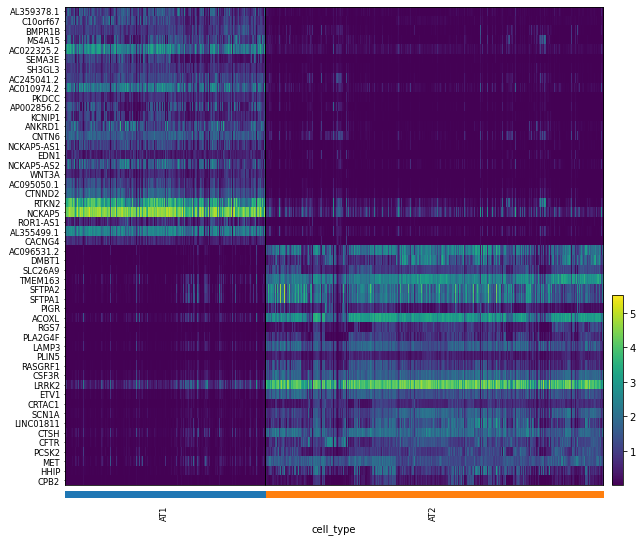

In [ ]:

sc.pl.heatmap(subset, genes_to_show, groupby='cell_type', swap_axes=True, layer = 'scvi_normalized',
              log = True)

# GO enrichment

In [ ]:
import gseapy as gp #this method requires internet connection

In [ ]:
gp.get_library_name()
# 'GO_Biological_Process_2021',
#'KEGG_2021_Human',

['ARCHS4_Cell-lines',
 'ARCHS4_IDG_Coexp',
 'ARCHS4_Kinases_Coexp',
 'ARCHS4_TFs_Coexp',
 'ARCHS4_Tissues',
 'Achilles_fitness_decrease',
 'Achilles_fitness_increase',
 'Aging_Perturbations_from_GEO_down',
 'Aging_Perturbations_from_GEO_up',
 'Allen_Brain_Atlas_10x_scRNA_2021',
 'Allen_Brain_Atlas_down',
 'Allen_Brain_Atlas_up',
 'Azimuth_Cell_Types_2021',
 'BioCarta_2013',
 'BioCarta_2015',
 'BioCarta_2016',
 'BioPlanet_2019',
 'BioPlex_2017',
 'CCLE_Proteomics_2020',
 'CORUM',
 'COVID-19_Related_Gene_Sets',
 'COVID-19_Related_Gene_Sets_2021',
 'Cancer_Cell_Line_Encyclopedia',
 'CellMarker_Augmented_2021',
 'ChEA_2013',
 'ChEA_2015',
 'ChEA_2016',
 'ChEA_2022',
 'Chromosome_Location',
 'Chromosome_Location_hg19',
 'ClinVar_2019',
 'DSigDB',
 'Data_Acquisition_Method_Most_Popular_Genes',
 'DepMap_WG_CRISPR_Screens_Broad_CellLines_2019',
 'DepMap_WG_CRISPR_Screens_Sanger_CellLines_2019',
 'Descartes_Cell_Types_and_Tissue_2021',
 'Diabetes_Perturbations_GEO_2022',
 'DisGeNET',
 'Disease_

In [ ]:
subset

AnnData object with n_obs × n_vars = 17392 × 12705
    obs: 'Sample', 'doublet', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', '_scvi_batch', '_scvi_labels', 'leiden', '_scvi_raw_norm_scaling', 'cell_type', 'condition'
    var: 'n_cells'
    uns: 'Sample_colors', '_scvi_manager_uuid', '_scvi_uuid', 'cell type_colors', 'leiden', 'leiden_colors', 'log1p', 'markers', 'neighbors', 'rank_genes_groups', 'scvi_markers', 'umap', 'cell_type_colors'
    obsm: 'X_scVI', 'X_umap', '_scvi_extra_categorical_covs', '_scvi_extra_continuous_covs'
    layers: 'counts', 'scvi_normalized'
    obsp: 'connectivities', 'distances'

In [ ]:
enr = gp.enrichr(gene_list= dedf[dedf.log2fc > 0].gene.tolist(),
                 gene_sets=['KEGG_2021_Human','GO_Biological_Process_2021'],
                 organism='human', # don't forget to set organism to the one you desired!
                 outdir=None, # don't write to disk,
                 background = subset.var_names.tolist()
                )

/home/jrlab2019/miniconda3/envs/sc/lib/python3.9/site-packages/gseapy/enrichr.py:427: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  self.results = self.results.append(res, ignore_index=True)
/home/jrlab2019/miniconda3/envs/sc/lib/python3.9/site-packages/gseapy/enrichr.py:427: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  self.results = self.results.append(res, ignore_index=True)


In [ ]:
enr.results

,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Odds Ratio,Combined Score,Genes
0,KEGG_2021_Human,Focal adhesion,29/201,7.316495e-14,1.785225e-11,0,0,6.602599,199.702610,ITGB1;LAMA5;LAMA3;LAMC2;PIK3R1;ARHGAP5;IGF1R;E...
1,KEGG_2021_Human,Adherens junction,14/71,3.522079e-09,4.296936e-07,0,0,9.389902,182.767065,FARP2;ACTN1;LMO7;ACTN4;PTPRF;RHOA;IGF1R;TJP1;A...
2,KEGG_2021_Human,ECM-receptor interaction,14/88,6.269589e-08,5.099265e-06,0,0,7.226431,119.850144,ITGB1;LAMA5;LAMB3;ITGA3;ITGA2;LAMA3;LAMC2;HSPG...
3,KEGG_2021_Human,Tight junction,19/169,9.770140e-08,5.447448e-06,0,0,4.867223,78.563555,ITGB1;ACTN1;RDX;ACTN4;CGN;PRKCZ;RHOA;TJP1;AFDN...
4,KEGG_2021_Human,Small cell lung cancer,14/92,1.116280e-07,5.447448e-06,0,0,6.854432,109.726383,ITGB1;LAMA5;LAMB3;ITGA3;ITGA2;LAMA3;LAMC2;PIK3...
...,...,...,...,...,...,...,...,...,...,...
2894,GO_Biological_Process_2021,gene expression (GO:0010467),3/356,9.956803e-01,9.971826e-01,0,0,0.313170,0.001356,TSPAN5;BICD1;RBMS2
2895,GO_Biological_Process_2021,translation (GO:0006412),1/214,9.966190e-01,9.977464e-01,0,0,0.173601,0.000588,EEF2K
2896,GO_Biological_Process_2021,"transcription, DNA-templated (GO:0006351)",1/221,9.971957e-01,9.979474e-01,0,0,0.168016,0.000472,MED4
2897,GO_Biological_Process_2021,cellular macromolecule biosynthetic process (G...,2/314,9.977853e-01,9.981612e-01,0,0,0.236267,0.000524,EEF2K;RPA3


## comparisons

/home/jrlab2019/miniconda3/envs/sc/lib/python3.9/site-packages/anndata/compat/_overloaded_dict.py:106: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  self.data[key] = value


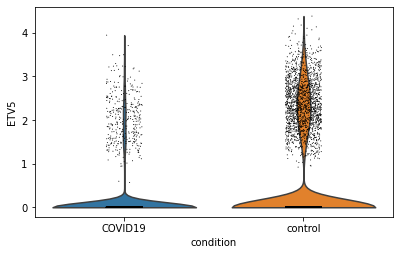

In [ ]:
sc.pl.violin(subset[subset.obs.cell_type == 'AT2'], 'ETV5', groupby='condition')

In [ ]:
from scipy import stats

In [ ]:
temp = subset[subset.obs.cell_type == 'AT2']

i = np.where(temp.var_names == 'ETV5')[0][0]

In [ ]:
a = temp[temp.obs.condition == 'COVID19'].X[:,i]
b = temp[temp.obs.condition == 'control'].X[:,i]

In [ ]:
stats.mannwhitneyu(a, b)

MannwhitneyuResult(statistic=11610070.0, pvalue=2.7473453476664947e-108)

## Score gene signature

In [ ]:
#gene signature, ie, input list of genes from user
with open('datp_sig.txt') as f:
    datp_sig = [x.strip() for x in list(f)]


In [ ]:
sc.tl.score_genes(subset, datp_sig, score_name = 'datp')

/home/jrlab2019/miniconda3/envs/sc/lib/python3.9/site-packages/scanpy/tools/_score_genes.py:151: FutureWarning: Passing a set as an indexer is deprecated and will raise in a future version. Use a list instead.
  for cut in np.unique(obs_cut.loc[gene_list]):


In [ ]:
subset.obs

,Sample,doublet,n_genes,n_genes_by_counts,total_counts,total_counts_mt,pct_counts_mt,total_counts_ribo,pct_counts_ribo,_scvi_batch,_scvi_labels,leiden,_scvi_raw_norm_scaling,cell_type,condition,datp
TTTGACTAGAGCCGAT-1_15,L08cov,False,2576,2576,5714.0,0.0,0.0,1.0,0.017501,0,0,4,1.754386,AT1,COVID19,0.149879
TTAGTCTGTATTTCCT-1_15,L08cov,False,2546,2546,5608.0,0.0,0.0,19.0,0.338802,0,0,9,1.787630,AT2,COVID19,0.462444
GGTGATTAGAGGATCC-1_15,L08cov,False,2531,2531,5489.0,0.0,0.0,0.0,0.000000,0,0,9,1.827819,AT2,COVID19,0.404560
GTTCCGTAGACCCGCT-1_15,L08cov,False,2295,2295,5465.0,0.0,0.0,3.0,0.054895,0,0,4,1.832845,AT1,COVID19,0.350152
CAGATTGCACTAACCA-1_15,L08cov,False,2287,2287,5184.0,0.0,0.0,0.0,0.000000,0,0,4,1.932741,AT1,COVID19,0.297367
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
AGCTTCCAGGCATGCA-1_27,L22cov,False,360,360,407.0,0.0,0.0,0.0,0.000000,0,0,9,24.570024,AT2,COVID19,0.094823
GCACGGTCAGAAGTTA-1_27,L22cov,False,336,336,402.0,0.0,0.0,0.0,0.000000,0,0,9,24.937656,AT2,COVID19,-0.011838
TTGTGGATCATAGGCT-1_27,L22cov,False,329,329,406.0,0.0,0.0,1.0,0.246305,0,0,9,24.752476,AT2,COVID19,0.064200
GCCGATGAGTAAACGT-1_27,L22cov,False,326,326,401.0,0.0,0.0,8.0,1.995013,0,0,3,25.000000,AT2,COVID19,0.147274


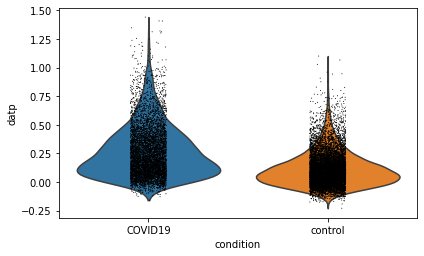

In [ ]:
sc.pl.violin(subset, 'datp', groupby='condition')

In [ ]:
a = subset[subset.obs.condition == 'COVID19'].obs.datp.values
b = subset[subset.obs.condition == 'control'].obs.datp.values
stats.mannwhitneyu(a, b)

MannwhitneyuResult(statistic=50960539.0, pvalue=0.0)

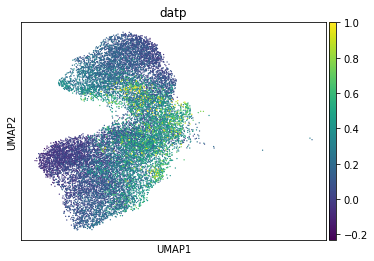

In [ ]:
sc.pl.umap(subset, color = 'datp', vmax = 1)

In [ ]:
#for thumbnail

In [ ]:
from matplotlib.pyplot import rc_context


In [ ]:
adata

AnnData object with n_obs × n_vars = 98979 × 20631
    obs: 'Sample', 'doublet', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', '_scvi_batch', '_scvi_labels', 'leiden', '_scvi_raw_norm_scaling', 'cell type'
    var: 'n_cells'
    uns: 'Sample_colors', '_scvi_manager_uuid', '_scvi_uuid', 'cell type_colors', 'leiden', 'leiden_colors', 'log1p', 'markers', 'neighbors', 'rank_genes_groups', 'scvi_markers', 'umap'
    obsm: 'X_scVI', 'X_umap', '_scvi_extra_categorical_covs', '_scvi_extra_continuous_covs'
    layers: 'counts', 'scvi_normalized'
    obsp: 'connectivities', 'distances'

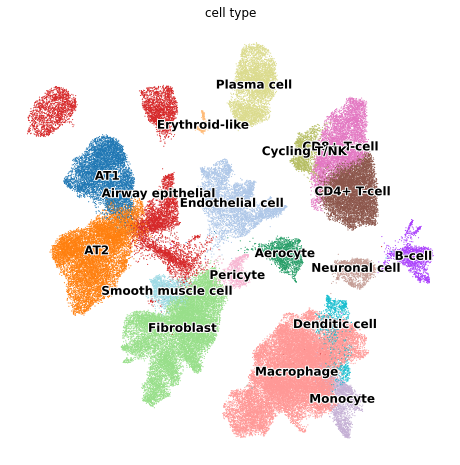

In [ ]:
with rc_context({'figure.figsize': (8,8)}):
    sc.pl.umap(adata, color = ['cell type'], frameon = False, s = 5, legend_loc = 'on data',
              legend_fontsize=12, legend_fontoutline=2)

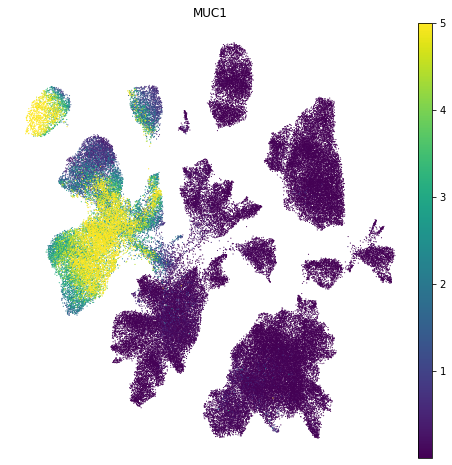

In [ ]:
with rc_context({'figure.figsize': (8,8)}):
    sc.pl.umap(adata, color = ['MUC1'], frameon = False, layer = 'scvi_normalized', vmax = 5, s = 5)